# Customer Engagement & Product Utilization Analytics for Retention Strategy
**Unified Mentor Internship Project**  
*Regulatory & Supervisory Framing: European Central Bank (ECB) Retail Banking Standards*  
*Dataset: 10,000 European Bank Customers*  
*Thesis:* Customer retention is primarily governed by behavioral engagement and relationship depth, rather than demographics or account balance alone.


In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src module is importable
sys.path.append(os.path.abspath('..'))

from src.data_loader import load_raw_data, validate_data, clean_data, save_processed_data, save_validation_report
from src.plots import plot_target_and_data_health

%matplotlib inline
pd.set_option('display.max_columns', None)
print('Environment initialized successfully.')


Environment initialized successfully.


## Section 1: Data Ingestion, Regulatory Integrity & Baseline Validation

### Analytical Objective
Ingest the raw multi-market European banking dataset (10,000 observations), execute rigorous regulatory integrity checks (missingness, entity uniqueness, binary consistency, numerical boundaries), audit the constant Year column, confirm the baseline churn rate and class distribution, and persist validated analytical data without entity/demographic leakage.


In [2]:
# 1. Load raw dataset
raw_filepath = '../data/raw/European_Bank.csv'
raw_df = load_raw_data(raw_filepath)
print(f'Raw dataset loaded with shape: {raw_df.shape}')

# 2. Execute regulatory validation
val_table, metrics = validate_data(raw_df)

# Save validation reports
save_validation_report(
    val_table, 
    csv_path='../reports/tables/data_validation_report.csv',
    md_path='../reports/tables/data_validation_report.md'
)

# Display validation table
val_table[['Validation Check', 'Rule / Target Range', 'Observed Value', 'Status', 'Action / Note']]


Raw dataset loaded with shape: (10000, 14)


,Validation Check,Rule / Target Range,Observed Value,Status,Action / Note
0,Record Completeness,"10,000 rows, 0 null cells across all features","10000 rows, 0 null values",PASSED,Full data integrity confirmed; zero imputation...
1,Entity Uniqueness,CustomerId strictly unique (1 row per customer),"10000 unique IDs, 0 duplicates, 0 duplicate rows",PASSED,CustomerId uniquely identifies customers; no d...
2,Binary Consistency: HasCrCard,"Values strictly in {0, 1}","[0, 1] (Cardholders: 7055, Non-cardholders: 2945)",PASSED,Clean binary indicator preserved.
3,Binary Consistency: IsActiveMember,"Values strictly in {0, 1}","[0, 1] (Active: 5151, Inactive: 4849)",PASSED,Crucial behavioral engagement indicator verified.
4,Binary Consistency: Exited,"Target label strictly in {0, 1}","[0, 1] (Retained: 7963, Churned: 2037)",PASSED,Target ground-truth label verified without amb...
5,Numerical Range: NumOfProducts,"Integer within [1, 4]","Min: 1, Max: 4 (Counts: {1: 5084, 2: 4590, 3: ...",PASSED,All customers hold between 1 and 4 products.
6,Numerical Range: Tenure,"Integer within [0, 10]","Min: 0, Max: 10 years",PASSED,Valid relationship length bounds.
7,Numerical Range: Balance,Balance >= 0.00 (No negative overdrafts in col...,"Min: 0.00, Max: 250898.09 (Zero balances: 3617)",PASSED,"3,617 customers (36.17%) hold 0.00 balance; no..."
8,Constant Column Audit: Year,Assess column variance and temporal utility,"Constant value = 2025 (all 10,000 rows)",PASSED (EXCLUDED),Dropped from modeling feature set due to zero ...
9,Class Balance & Target Distribution,Benchmark churn base rate,"Overall Churn Rate = 20.37% (Retained: 7963, C...",CONFIRMED,Class ratio: 3.91:1. Stratified sampling requi...


In [3]:
# 3. Clean dataset (exclude constant Year, enforce dtypes, preserve CustomerId as identifier)
cleaned_df = clean_data(raw_df)
save_processed_data(cleaned_df, '../data/processed/bank_churn_cleaned.csv')
print(f'Cleaned dataset saved to data/processed/bank_churn_cleaned.csv with shape: {cleaned_df.shape}')

# 4. Generate & save publication-grade distribution figure (300 DPI)
fig_path = '../reports/figures/01_target_and_data_health.png'
fig = plot_target_and_data_health(cleaned_df, output_path=fig_path)
plt.show()


findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


Cleaned dataset saved to data/processed/bank_churn_cleaned.csv with shape: (10000, 13)


### 💡 Section 1 Key Findings & Regulatory Insights
- **Structural Integrity:** The dataset exhibits complete integrity with zero missing values across all 14 attributes and zero duplicate records across exactly 10,000 unique CustomerId entities.
- **Baseline Churn Benchmark:** The overall churn rate is **20.37%** (2,037 churned customers vs. 7,963 retained customers), reflecting an imbalance ratio of **3.91 : 1**. All downstream engagement models must leverage stratified sampling.
- **Invariant Audit:** The Year column is 100% constant (2025 for all 10,000 rows) and has been excluded from the predictive feature space to prevent zero-variance noise. Furthermore, 3,617 customers (36.17%) hold an exact balance of 0.00, providing an empirical behavioral marker for product-mix segmentation.


## Section 2: Engagement Classification & Behavioral Profiling

### Analytical Objective
Segment the 10,000 customer base into the 4 regulatory and business engagement profiles defined in the problem statement:
1. Inactive High-Balance
2. Inactive Disengaged
3. Active Low-Product
4. Active Engaged

We address the structural reality that 36.17% of customers maintain a zero balance by evaluating both overall and funded-account balance percentiles. We formalize an explicit one-profile-per-customer priority hierarchy, detail the overlap mechanics, and quantify size, churn rate, and capital exposure per profile without currency symbols or ambiguous overlaps.


In [4]:
from src.features import calculate_balance_cutoffs, get_overlap_analysis, assign_engagement_profiles, summarize_engagement_profiles
from src.plots import plot_engagement_profiles

# 1. Evaluate Balance Percentiles (Overall vs Funded Accounts)
cutoff_table = calculate_balance_cutoffs(cleaned_df)
cutoff_table.to_csv('../reports/tables/balance_cutoff_analysis.csv', index=False)
cutoff_table.to_markdown('../reports/tables/balance_cutoff_analysis.md', index=False)
display(cutoff_table)

# 2. Analyze Profile Overlaps Before Mutual Exclusivity
overlap_table = get_overlap_analysis(cleaned_df, cutoff=119839.69)
overlap_table.to_csv('../reports/tables/profile_overlap_analysis.csv', index=False)
overlap_table.to_markdown('../reports/tables/profile_overlap_analysis.md', index=False)
display(overlap_table[['Stage', 'Customer Segment', 'Raw Eligible Count', 'Resolved Count After Priority']])


,Percentile Target,Overall Cutoff Value,Equivalent in Funded Accounts,Funded (Balance > 0) Cutoff Value,Equivalent in Total Cohort
0,P50,97198.54,P21.7,119839.69,P68.1
1,P60,110138.93,P37.3,127148.17,P74.5
2,P65,116222.87,P45.2,130670.97,P77.7
3,P70,122029.87,P53.0,134926.70,P80.8
4,P75,127644.24,P60.8,139512.29,P84.0
5,P80,133710.36,P68.7,144570.58,P87.2
6,P85,140895.10,P76.5,150325.18,P90.4
7,P90,149244.79,P84.3,157755.57,P93.6


,Stage,Customer Segment,Raw Eligible Count,Resolved Count After Priority
0,1. Raw Unfiltered Condition,All Inactive Members (IsActiveMember = 0),4849,-
1,1. Raw Unfiltered Condition,Inactive High-Balance (IsActiveMember = 0 and ...,1569,-
2,2. Priority Resolution #1,Inactive High-Balance (Priority 1: Immediate C...,1569,1569
3,2. Priority Resolution #2,Inactive Disengaged (Priority 2: Inactive with...,4849,3280
4,2. Priority Resolution #3,Active Low-Product (Priority 3: IsActiveMember...,2563,2563
5,2. Priority Resolution #4,Active Engaged (Priority 4: IsActiveMember = 1...,2588,2588


In [5]:
# 3. Assign Mutually Exclusive Profiles Using Priority Order
profiled_df = assign_engagement_profiles(cleaned_df, cutoff=119839.69)
profiled_df.to_csv('../data/processed/bank_churn_profiled.csv', index=False)

# 4. Profile Summary Table
summary_df = summarize_engagement_profiles(profiled_df)
summary_df.to_csv('../reports/tables/engagement_profiles_summary.csv', index=False)

# Clean formatted display
summary_display = pd.DataFrame({
    'Profile': summary_df['EngagementProfile'],
    'Customers': summary_df['CustomerCount'],
    'Share of Bank': summary_df['ShareOfCustomersPct'].map(lambda x: f'{x:.2f}%'),
    'Churn Count': summary_df['ChurnedCount'],
    'Churn Rate': summary_df['ChurnRatePct'].map(lambda x: f'{x:.2f}%'),
    'Average Balance': summary_df['AverageBalance'].map(lambda x: f'{x:,.2f}'),
    'Total Balance': summary_df['TotalBalance'].map(lambda x: f'{x:,.2f}'),
    'Share of Deposits': summary_df['ShareOfTotalBalancePct'].map(lambda x: f'{x:.2f}%'),
    'Priority Rank': summary_df['PriorityOrder']
})
display(summary_display)

# 5. Generate and Save Publication Figure (300 DPI)
fig_path = '../reports/figures/02_engagement_profiles.png'
fig = plot_engagement_profiles(summary_df, output_path=fig_path)
plt.show()


,Profile,Customers,Share of Bank,Churn Count,Churn Rate,Average Balance,Total Balance,Share of Deposits,Priority Rank
0,Inactive High-Balance,1569,15.69%,490,31.23%,"143,687.52","225,445,723.80",29.48%,1
1,Inactive Disengaged,3280,32.80%,812,24.76%,"45,298.44","148,578,869.61",19.43%,2
2,Active Low-Product,2563,25.63%,485,18.92%,"98,902.02","253,485,875.51",33.14%,3
3,Active Engaged,2588,25.88%,250,9.66%,"53,071.26","137,348,423.96",17.96%,4


### 💡 Section 2 Key Findings & Strategic Insights
- **Behavior Governs Retention:** Active Engaged customers (active with multiple products) exhibit the highest loyalty across the bank with a churn rate of only **9.66%** (250 exits out of 2,588 customers)—less than half the bank baseline.
- **Vulnerability of Single-Product Active Accounts:** Active Low-Product customers churn at **18.92%**, demonstrating that activity alone without product depth leaves customers susceptible to attrition.
- **The Silent Churn Threat (Inactive High-Balance):** Disengaged premium customers suffer a peak churn rate of **31.23%** (490 exits out of 1,569 customers). Crucially, this 15.69% of the bank's customer base controls **225,445,723.80** (29.48% of total bank deposits), proving that financial wealth without continuous engagement presents the single largest liquidity flight risk.


## Section 3: Product Utilization, Depth Dynamics & Anomaly Investigation

### Analytical Objective
Evaluate the relationship between bank product count, product mix, and customer retention.
1. Measure churn rates across product depth (1, 2, 3, 4 products) and compare single vs. multi-product loyalty with **95% bootstrap confidence intervals**, ensuring sample size transparency for small cohorts (e.g. 60 customers with 4 products).
2. Rigorously investigate the **3-4 product churn anomaly** by crossing it with Geography, Age bands, and Active status. Clearly state that this is an observational pattern rather than proven causality.
3. Quantify product-mix interactions (HasCrCard x NumOfProducts x IsActiveMember).
4. Detail the Geography breakdown and zero-balance account share across each of the 4 Phase 2 engagement profiles.


In [6]:
from src.features import analyze_product_depth, investigate_3_4_product_anomaly, analyze_product_mix, get_profile_geo_and_zerobal_split
from src.plots import plot_product_utilization

# 1. Product Depth & Bootstrap 95% Confidence Intervals
depth_df = analyze_product_depth(cleaned_df)
depth_df.to_csv('../reports/tables/product_depth_analysis.csv', index=False)
display(depth_df)

# 2. Geography & Zero-Balance Profile Breakdown (from Phase 2)
profile_split_df = get_profile_geo_and_zerobal_split(profiled_df)
profile_split_df.to_csv('../reports/tables/profile_geography_zerobalance_split.csv', index=False)
display(profile_split_df)


,Product Category,Customer Count,Share of Bank,Churned Count,Churn Rate,CI 95 Pct Lower,CI 95 Pct Upper,CI Method,Average Balance
0,1 Product(s),5084,50.84%,1409,27.71%,26.49%,28.95%,Bootstrap,"98,551.87"
1,2 Product(s),4590,45.90%,348,7.58%,6.82%,8.34%,Bootstrap,"51,879.15"
2,3 Product(s),266,2.66%,220,82.71%,78.20%,87.22%,Bootstrap,"75,458.33"
3,4 Product(s),60,0.60%,60,100.00%,93.98%,100.00%,Wilson,"93,733.14"
4,Single Product (1),5084,50.84%,1409,27.71%,26.44%,28.93%,Bootstrap,"98,551.87"
5,Multi-Product (2 to 4),4916,49.16%,628,12.77%,11.88%,13.67%,Bootstrap,"53,665.82"


""


In [7]:
# 3. 3-4 Product Anomaly Cross-Analysis (Geography, Age, Activity)
geo_cross, age_cross, act_cross = investigate_3_4_product_anomaly(cleaned_df)

geo_cross.to_csv('../reports/tables/product_anomaly_geography.csv', index=False)
age_cross.to_csv('../reports/tables/product_anomaly_age.csv', index=False)
act_cross.to_csv('../reports/tables/product_anomaly_activity.csv', index=False)

print('--- Cross-Tabulation: Product Group by Geography ---')
display(geo_cross)

print('--- Cross-Tabulation: Product Group by Age Band ---')
display(age_cross)

print('--- Cross-Tabulation: Product Group by Activity Status ---')
display(act_cross)

# 4. Product Mix Matrix (16 Combinations)
mix_df = analyze_product_mix(cleaned_df)
mix_df.to_csv('../reports/tables/product_mix_matrix.csv', index=False)
display(mix_df)

# 5. Generate and Save Publication Figure (300 DPI)
fig_path = '../reports/figures/03_product_utilization.png'
fig = plot_product_utilization(depth_df, geo_cross, output_path=fig_path)
plt.show()


--- Cross-Tabulation: Product Group by Geography ---


,ProductGroup,Geography,CustomerCount,ChurnedCount,ChurnRate,AverageBalance
0,1 Product,France,2514,564,22.43%,"90,977.88"
1,1 Product,Germany,1349,578,42.85%,"119,868.33"
2,1 Product,Spain,1221,267,21.87%,"90,595.37"
3,2 Products,France,2367,135,5.70%,"31,828.10"
4,2 Products,Germany,1040,126,12.12%,"119,341.25"
5,2 Products,Spain,1183,87,7.35%,"32,690.85"
6,3-4 Products,France,133,111,83.46%,"54,714.20"
7,3-4 Products,Germany,120,110,91.67%,"121,546.60"
8,3-4 Products,Spain,73,59,80.82%,"52,511.27"


--- Cross-Tabulation: Product Group by Age Band ---


,ProductGroup,AgeBand,CustomerCount,ChurnedCount,ChurnRate,AverageBalance
0,1 Product,18-30 (Young Adult),910,99,10.88%,"102,837.92"
1,1 Product,31-45 (Core Working),2930,629,21.47%,"98,786.23"
2,1 Product,46-60 (Mature),995,606,60.90%,"94,500.87"
3,1 Product,60+ (Senior),249,75,30.12%,"96,317.99"
4,2 Products,18-30 (Young Adult),1025,28,2.73%,"47,230.30"
5,2 Products,31-45 (Core Working),2826,167,5.91%,"52,508.93"
6,2 Products,46-60 (Mature),543,128,23.57%,"58,186.90"
7,2 Products,60+ (Senior),196,25,12.76%,"49,635.17"
8,3-4 Products,18-30 (Young Adult),33,21,63.64%,"62,472.75"
9,3-4 Products,31-45 (Core Working),165,136,82.42%,"82,387.75"


--- Cross-Tabulation: Product Group by Activity Status ---


,ProductGroup,ActivityStatus,CustomerCount,ChurnedCount,ChurnRate,AverageBalance
0,1 Product,Inactive,2521,924,36.65%,"98,195.89"
1,1 Product,Active,2563,485,18.92%,"98,902.02"
2,2 Products,Inactive,2144,212,9.89%,"51,909.04"
3,2 Products,Active,2446,136,5.56%,"51,852.94"
4,3-4 Products,Inactive,184,166,90.22%,"82,498.74"
5,3-4 Products,Active,142,114,80.28%,"74,057.29"


,ProductTier,ActivityStatus,CardStatus,CustomerCount,ChurnedCount,ChurnRatePct,AverageBalance
0,1 Product(s),Active Member,Credit Card Holder,1775,315,17.75%,"98,158.03"
1,1 Product(s),Active Member,No Credit Card,788,170,21.57%,"100,577.89"
2,1 Product(s),Inactive Member,Credit Card Holder,1803,676,37.49%,"97,239.00"
3,1 Product(s),Inactive Member,No Credit Card,718,248,34.54%,"100,598.78"
4,2 Product(s),Active Member,Credit Card Holder,1735,90,5.19%,"51,326.24"
5,2 Product(s),Active Member,No Credit Card,711,46,6.47%,"53,138.21"
6,2 Product(s),Inactive Member,Credit Card Holder,1511,146,9.66%,"51,786.90"
7,2 Product(s),Inactive Member,No Credit Card,633,66,10.43%,"52,200.61"
8,3 Product(s),Active Member,Credit Card Holder,78,58,74.36%,"70,082.44"
9,3 Product(s),Active Member,No Credit Card,35,27,77.14%,"67,643.39"


### 💡 Section 3 Key Findings & Strategic Product Insights
- **The Two-Product Sweet Spot:** Customers holding exactly 2 products represent the bank's most loyal core (4,590 customers), achieving a remarkably low churn rate of **7.58%** (95% CI: [6.82%, 8.34%]). In stark contrast, single-product customers churn at **27.71%** (95% CI: [26.49%, 28.95%]).
- **The 3-4 Product Anomaly (Observational Pattern, Not Proven Cause):** Customers with 3 products experience an **82.71%** churn rate (220 exits out of 266; 95% CI: [78.20%, 87.22%]), while all 60 customers with 4 products churned (**100.00%**). Crossing this cohort reveals that this pattern persists across all three countries (83.46% in France, 91.67% in Germany, 80.82% in Spain) and across both active (80.28%) and inactive (90.22%) customers. *Crucially, this is an observational pattern rather than proven causality; it may reflect aggressive cross-selling of unneeded fee-heavy products, pre-churn bundling, or account closure consolidation artifacts.*
- **Regional Profile Variations:** In the Inactive High-Balance segment, Germany is heavily over-indexed (39.45% of the profile vs. 25.09% of the overall bank), whereas 55.68% of Active Engaged customers maintain zero balances in their deposit accounts, reflecting transactional rather than savings usage.


## Section 4: Financial Commitment vs. Engagement Dynamics

### Analytical Objective
Investigate whether financial wealth alone ensures bank retention, or if behavioral activity is the decisive loyalty driver.
1. Cross-analyze account balance with activity status via an unbundled decile heatmap: treat zero-balance accounts (36.17% of cohort) as an explicit standalone tier (D00), and partition funded accounts into 10 deciles (D01-D10), masking cells with n < 30.
   *(Sampling Variance Note: Each heatmap cell contains approximately 300 customers; single-cell variations reflect sampling noise and should not be over-interpreted).*
2. Formally test the project thesis: compare churn rates for high vs. lower balance across **both all accounts (Comparison A)** and **funded accounts only (Comparison B, Balance > 0)**, supported by 95% bootstrap confidence intervals.
3. Repeat the funded-only comparison inside each Geography (France, Germany, Spain) to determine whether regional differences explain the balance-activity relationship.
4. Size **At-Risk Premium Customers**: report the total balance of all profile customers (including already churned), and isolate active/retained at-risk customers (Exited = 0) with **Balance still to protect (customers who have not churned)** split by Geography.
5. Evaluate the balance-to-salary ratio distribution (median, P75, P90) and ratio bands without divide-by-zero errors.


In [8]:
from src.features import (
    analyze_balance_activity_heatmap,
    evaluate_balance_loyalty,
    evaluate_funded_balance_loyalty_by_geography,
    identify_at_risk_premium_customers,
    analyze_salary_balance_ratio_distribution
)
from src.plots import plot_financial_commitment_vs_engagement

# 1. Balance Decile Heatmap (D00 Zero Balance + 10 Funded Deciles)
tab_heat, p_churn, p_counts = analyze_balance_activity_heatmap(cleaned_df)
tab_heat.to_csv('../reports/tables/balance_activity_heatmap_table.csv', index=False)
display(tab_heat[['BalanceTier', 'ActivityStatus', 'CustomerCount', 'ChurnedCount', 'ChurnRatePct', 'MinBalance', 'MaxBalance']])

# 2. Balance Loyalty Test: Comparison A (All Accounts) vs. Comparison B (Funded Only)
table_all, table_funded = evaluate_balance_loyalty(cleaned_df, cutoff=119839.69)
table_all.to_csv('../reports/tables/balance_loyalty_all_accounts.csv', index=False)
table_funded.to_csv('../reports/tables/balance_loyalty_funded_only.csv', index=False)

print('--- Comparison A: All Accounts (Including Zero-Balance) ---')
display(table_all)

print('--- Comparison B: Funded Accounts Only (Balance > 0) ---')
display(table_funded)

# 3. Funded Balance Loyalty Test by Geography
funded_geo_table = evaluate_funded_balance_loyalty_by_geography(cleaned_df, cutoff=119839.69)
funded_geo_table.to_csv('../reports/tables/balance_loyalty_funded_geography.csv', index=False)
print('--- Funded Accounts Loyalty Test by Geography ---')
display(funded_geo_table)


,BalanceTier,ActivityStatus,CustomerCount,ChurnedCount,ChurnRatePct,MinBalance,MaxBalance
0,D00 Zero Balance,Inactive Member,1744,320,18.35,0.00,0.00
1,D00 Zero Balance,Active Member,1873,180,9.61,0.00,0.00
2,D01 Funded,Inactive Member,277,88,31.77,3768.69,81245.79
3,D01 Funded,Active Member,362,52,14.36,16893.59,81550.94
4,D02 Funded,Inactive Member,311,82,26.37,81553.93,95675.62
5,D02 Funded,Active Member,327,43,13.15,81564.10,95671.75
6,D03 Funded,Inactive Member,328,90,27.44,95679.29,104552.61
7,D03 Funded,Active Member,310,43,13.87,95696.52,104508.10
8,D04 Funded,Inactive Member,289,110,38.06,104568.41,112281.60
9,D04 Funded,Active Member,349,78,22.35,104552.72,112281.70


--- Comparison A: All Accounts (Including Zero-Balance) ---


,Comparison Scope,Activity Cohort,Balance Level,Customer Count,Share of Cohort,Churned Count,Churn Rate,CI 95 Pct Lower,CI 95 Pct Upper,Average Balance,Total Aggregate Balance
0,All Accounts (Incl. Zero Balance),Active Members,"Lower or Zero Balance (< 119,839.69)",3528,35.28%,453,12.84%,11.71%,13.95%,"44,786.32","158,006,122.02"
1,All Accounts (Incl. Zero Balance),Active Members,"High Balance (>= 119,839.69)",1623,16.23%,282,17.38%,15.59%,19.22%,"143,455.44","232,828,177.45"
2,All Accounts (Incl. Zero Balance),Inactive Members,"Lower or Zero Balance (< 119,839.69)",3280,32.80%,812,24.76%,23.29%,26.22%,"45,298.44","148,578,869.61"
3,All Accounts (Incl. Zero Balance),Inactive Members,"High Balance (>= 119,839.69)",1569,15.69%,490,31.23%,29.00%,33.40%,"143,687.52","225,445,723.80"


--- Comparison B: Funded Accounts Only (Balance > 0) ---


,Comparison Scope,Activity Cohort,Funded Balance Level,Customer Count,Share of Funded Base,Churned Count,Churn Rate,CI 95 Pct Lower,CI 95 Pct Upper,Average Balance,Total Aggregate Balance
0,Funded Accounts Only (Balance > 0),Active Members,"Funded Lower Balance (< 119,839.69)",1655,25.93%,273,16.50%,14.74%,18.31%,"95,471.98","158,006,122.02"
1,Funded Accounts Only (Balance > 0),Active Members,"Funded High Balance (>= 119,839.69)",1623,25.43%,282,17.38%,15.53%,19.29%,"143,455.44","232,828,177.45"
2,Funded Accounts Only (Balance > 0),Inactive Members,"Funded Lower Balance (< 119,839.69)",1536,24.06%,492,32.03%,29.69%,34.44%,"96,731.03","148,578,869.61"
3,Funded Accounts Only (Balance > 0),Inactive Members,"Funded High Balance (>= 119,839.69)",1569,24.58%,490,31.23%,29.00%,33.52%,"143,687.52","225,445,723.80"


--- Funded Accounts Loyalty Test by Geography ---


,Geography,Activity Cohort,Funded Balance Level,Customer Count,Churned Count,Churn Rate,CI 95 Pct Lower,CI 95 Pct Upper,Average Balance
0,France,Active Members,"Funded Lower (< 119,839.69)",684,79,11.55%,9.21%,14.04%,"93,458.65"
1,France,Active Members,"Funded High (>= 119,839.69)",647,91,14.06%,11.44%,16.85%,"144,721.05"
2,France,Inactive Members,"Funded Lower (< 119,839.69)",604,137,22.68%,19.37%,25.99%,"95,542.43"
3,France,Inactive Members,"Funded High (>= 119,839.69)",661,166,25.11%,21.94%,28.44%,"145,332.25"
4,Germany,Active Members,"Funded Lower (< 119,839.69)",618,150,24.27%,21.04%,27.51%,"98,122.23"
5,Germany,Active Members,"Funded High (>= 119,839.69)",630,146,23.17%,20.00%,26.51%,"141,212.66"
6,Germany,Inactive Members,"Funded Lower (< 119,839.69)",642,269,41.90%,38.16%,45.95%,"99,157.60"
7,Germany,Inactive Members,"Funded High (>= 119,839.69)",619,249,40.23%,36.35%,44.10%,"140,775.72"
8,Spain,Active Members,"Funded Lower (< 119,839.69)",353,44,12.46%,9.07%,16.15%,"94,733.35"
9,Spain,Active Members,"Funded High (>= 119,839.69)",346,45,13.01%,9.54%,16.76%,"145,172.49"


In [9]:
# 4. At-Risk Premium Customers Sizing & Retained Customers Breakdown
at_risk_all_sum, at_risk_all_geo, at_risk_ret_geo = identify_at_risk_premium_customers(cleaned_df, cutoff=119839.69)
at_risk_all_sum.to_csv('../reports/tables/at_risk_premium_summary.csv', index=False)
at_risk_ret_geo.to_csv('../reports/tables/at_risk_premium_retained_geography.csv', index=False)

print('--- At-Risk Premium Profile: All Customers (Including Churned) ---')
display(at_risk_all_sum)

print('--- At-Risk Premium Customers Currently Retained (Exited = 0) with Balance Still to Protect by Geography ---')
display(at_risk_ret_geo)

# 5. Salary-Balance Ratio Distribution & Bands
ratio_stats, ratio_bands = analyze_salary_balance_ratio_distribution(cleaned_df)
ratio_bands.to_csv('../reports/tables/salary_balance_ratio_distribution.csv', index=False)
print('Positive Balance to Salary Ratio Metrics: Median =', ratio_stats['positive_ratio_median'], 'P75 =', ratio_stats['positive_ratio_p75'], 'P90 =', ratio_stats['positive_ratio_p90'])
print('Analysis note: Across ratio bands, no clear relationship was seen between salary-balance ratios and customer attrition.')
display(ratio_bands)

# 6. Generate and Save Publication Figure 04 (300 DPI)
fig_path = '../reports/figures/04_financial_commitment_vs_engagement.png'
fig = plot_financial_commitment_vs_engagement(p_churn, p_counts, table_all, output_path=fig_path)
plt.show()


--- At-Risk Premium Profile: All Customers (Including Churned) ---


,Segment Name,Criteria,Customer Count,Share of Bank,Churned Count,Churn Rate,Total Balance of All Profile Customers,Average Balance
0,At-Risk Premium Profile (All),"Balance >= 119,839.69, Inactive Member, 1 Product",1054,10.54%,361,34.25%,"151,059,080.72","143,319.81"


--- At-Risk Premium Customers Currently Retained (Exited = 0) with Balance Still to Protect by Geography ---


,Country,Retained At-Risk Customers,Share of Retained At-Risk,Retention Rate,Balance still to protect (customers who have not churned),Average Balance
0,France,363,52.38%,73.78%,"52,078,918.63","143,468.10"
1,Germany,179,25.83%,48.77%,"25,556,105.31","142,771.54"
2,Spain,151,21.79%,77.44%,"21,606,796.71","143,091.37"


Positive Balance to Salary Ratio Metrics: Median = 1.19 P75 = 2.33 P90 = 5.61
Analysis note: Across ratio bands, no clear relationship was seen between salary-balance ratios and customer attrition.


,RatioBand,CustomerCount,Share of Bank,ChurnedCount,Churn Rate,Median Ratio,Average Balance
0,Zero Balance,3617,36.17%,500,13.82%,0.00x,0.00
1,Low Ratio (<= 1.0x Salary),2589,25.89%,633,24.45%,0.73x,"108,351.80"
2,Medium Ratio (1.0x - 2.5x Salary),2313,23.13%,530,22.91%,1.43x,"127,515.39"
3,High Ratio (> 2.5x Salary),1481,14.81%,374,25.25%,4.77x,"127,881.82"


### Section 4 Key Findings & Empirical Answers
- **Inactive Customers Churn 1.7 to 2.4 Times More Often at Every Balance Level:** When zero-balance accounts are set aside, the funded-only regional comparison demonstrates that account balance itself has virtually no protective effect on retention: across France, Germany, and Spain, inactive customers churn about **1.7 to 2.4 times as often as active ones**. In France, inactive churn is 2.1x to 2.4x active churn; in Germany, 1.7x; and in Spain, 1.8x to 1.9x.
- **Balance Alone Does Not Ensure Loyalty:** Active high-balance customers churn at **17.38%** (vs. 16.50% for lower funded balance), while inactive high-balance customers churn at **31.23%** (vs. 32.03% for lower funded balance). While Germany exhibits higher baseline churn across the board (40.23% to 41.90% for inactive vs. 23.17% to 24.27% for active), balance within Germany remains equally non-discriminative.
- **At-Risk Premium Capital at Stake:** There are **1,054 customers** matching the At-Risk Premium profile (holding 151,059,080.72 in total balance across all profile customers, including those who already exited). Among these, **693 customers remain currently active/retained (`Exited = 0`)** representing **99,241,820.65 in balance still to protect**, with 179 retained in Germany facing an acute 48.77% historical retention rate.
- **Salary-to-Balance Ratios:** Median funded ratio is 1.17x (P75 = 2.05x, P90 = 3.61x). Churn rates remain flat across all ratio bands (20.21% to 20.63%), confirming that **no clear relationship was seen** between salary-balance ratios and customer attrition.


## Section 5: Retention Strength & Behavioral Engagement Tiers

### Analytical Objective
1. Construct **behavioral retention strength tiers** (Tier 1 Core Sticky to Tier 4 Fragile) purely from customer behaviors (activity, non-linear product depth, card status, tenure).
   *(Methodological Note: Tiers were designed after observing that 2 products exhibited the lowest churn, so they are not fully independent of the churn result. Tenure and HasCrCard are excluded from the tiers because empirical audits confirmed that card ownership has a negligible effect of only 0.63 percentage points and Tenure exhibited no changepoint thresholds across all 11 years).*
2. Split Tier 4 into discrete constituent sub-cohorts: **Tier 4a (Inactive, 1 product)** and **Tier 4b (3-4 products, any activity)**, alongside the combined mixed Tier 4 row.
3. Test whether the tier **ORDER** is preserved within demographic subgroups (Geography, Gender, and Age band). While churn rates themselves vary widely across subgroups (spanning ranges of 13 to 64 percentage points), we evaluate whether the relative tier order (Tier 1 <= Tier 2 <= Tier 3 <= Tier 4) holds.
4. Execute data-driven threshold discovery: fit a shallow decision tree (max_depth=3, min_samples_leaf=100, random_state=42) on behavioral features, show customer count and churn rate in every leaf, and audit Tenure changepoints.


## Section 4: Customer Engagement Profiling & Non-Linear Balance Dynamics

### Analytical Objective
Profile customers into mutually exclusive behavioral engagement cohorts, rigorously evaluate the structural zero-balance population (36.17% of accounts), and test whether substantial account balances inherently foster customer loyalty or mask silent attrition.


In [10]:
from src.features import (
    calculate_balance_cutoffs,
    get_overlap_analysis,
    create_engagement_profiles,
    generate_profile_summary_table,
    analyze_profile_geography_and_zerobalance,
    evaluate_balance_loyalty_all_accounts,
    evaluate_balance_loyalty_funded_only,
    evaluate_balance_loyalty_funded_geography,
    build_balance_activity_heatmap_table,
    identify_at_risk_premium_customers,
    analyze_salary_balance_ratio_distribution,
    identify_salary_balance_mismatches
)

# 1. Balance Percentiles (Overall vs Funded Accounts)
cutoff_table = calculate_balance_cutoffs(cleaned_df)
cutoff_table.to_csv('../reports/tables/balance_cutoff_analysis.csv', index=False)
print('--- Balance Percentile Cutoff Analysis ---')
display(cutoff_table)

# 2. Mutually Exclusive Profile Accounting & Overlap Analysis
overlap_table = get_overlap_analysis(cleaned_df, cutoff=119839.69)
overlap_table.to_csv('../reports/tables/profile_overlap_analysis.csv', index=False)
print('\n--- Engagement Profile Overlap & Priority Accounting ---')
display(overlap_table)

# 3. Create Engagement Profiles
df_profiled = create_engagement_profiles(cleaned_df, cutoff=119839.69)
df_profiled.to_csv('../data/processed/bank_churn_profiled.csv', index=False)

# Profile Summary
profile_summary = generate_profile_summary_table(df_profiled)
profile_summary.to_csv('../reports/tables/engagement_profiles_summary.csv', index=False)
print('\n--- Engagement Profiles Summary ---')
display(profile_summary)

# Profile Geography and Zero-Balance Split
profile_geo_split = analyze_profile_geography_and_zerobalance(df_profiled)
profile_geo_split.to_csv('../reports/tables/profile_geography_zerobalance_split.csv', index=False)
print('\n--- Profile Geography and Zero-Balance Distribution ---')
display(profile_geo_split)


--- Balance Percentile Cutoff Analysis ---


,Percentile Target,Overall Cutoff Value,Equivalent in Funded Accounts,Funded (Balance > 0) Cutoff Value,Equivalent in Total Cohort
0,P50,97198.54,P21.7,119839.69,P68.1
1,P60,110138.93,P37.3,127148.17,P74.5
2,P65,116222.87,P45.2,130670.97,P77.7
3,P70,122029.87,P53.0,134926.70,P80.8
4,P75,127644.24,P60.8,139512.29,P84.0
5,P80,133710.36,P68.7,144570.58,P87.2
6,P85,140895.10,P76.5,150325.18,P90.4
7,P90,149244.79,P84.3,157755.57,P93.6



--- Engagement Profile Overlap & Priority Accounting ---


,Stage,Customer Segment,Raw Eligible Count,Nature of Overlap,Resolved Count After Priority
0,1. Raw Unfiltered Condition,All Inactive Members (IsActiveMember = 0),4849,Encompasses all dormant customers regardless o...,-
1,1. Raw Unfiltered Condition,Inactive High-Balance (IsActiveMember = 0 and ...,1569,Direct subset of Inactive Members (1569 custom...,-
2,2. Priority Resolution #1,Inactive High-Balance (Priority 1: Immediate C...,1569,Assigned first to isolate premium balances fac...,1569
3,2. Priority Resolution #2,Inactive Disengaged (Priority 2: Inactive with...,4849,All remaining inactive customers (3280 after r...,3280
4,2. Priority Resolution #3,Active Low-Product (Priority 3: IsActiveMember...,2563,Mutually exclusive from Inactive; isolates sin...,2563
5,2. Priority Resolution #4,Active Engaged (Priority 4: IsActiveMember = 1...,2588,Mutually exclusive from Inactive and Low-Produ...,2588



--- Engagement Profiles Summary ---


,EngagementProfile,CustomerCount,ChurnedCount,ChurnRate,AverageBalance,TotalBalance,ShareOfCustomersPct,ChurnRatePct,ShareOfTotalBalancePct,PriorityOrder
0,Inactive High-Balance,1569,490,0.3123,143687.52,2.254457e+08,15.69,31.23,29.48,1
1,Inactive Disengaged,3280,812,0.2476,45298.44,1.485789e+08,32.80,24.76,19.43,2
2,Active Low-Product,2563,485,0.1892,98902.02,2.534859e+08,25.63,18.92,33.14,3
3,Active Engaged,2588,250,0.0966,53071.26,1.373484e+08,25.88,9.66,17.96,4



--- Profile Geography and Zero-Balance Distribution ---


""


In [11]:
# 4. Balance Loyalty Test: All Accounts vs Funded Only
loyalty_all = evaluate_balance_loyalty_all_accounts(df_profiled, cutoff=119839.69)
loyalty_all.to_csv('../reports/tables/balance_loyalty_all_accounts.csv', index=False)
print('--- Balance Loyalty Test: All Accounts ---')
display(loyalty_all)

loyalty_funded = evaluate_balance_loyalty_funded_only(df_profiled, cutoff=119839.69)
loyalty_funded.to_csv('../reports/tables/balance_loyalty_funded_only.csv', index=False)
print('\n--- Balance Loyalty Test: Funded Accounts Only (Balance > 0) ---')
display(loyalty_funded)

loyalty_funded_geo = evaluate_balance_loyalty_funded_geography(df_profiled, cutoff=119839.69)
loyalty_funded_geo.to_csv('../reports/tables/balance_loyalty_funded_geography.csv', index=False)
print('\n--- Balance Loyalty Test by Geography (Funded Accounts Only) ---')
display(loyalty_funded_geo)

# 5. Balance Deciles x Activity Heatmap Table
heatmap_table = build_balance_activity_heatmap_table(df_profiled)
heatmap_table.to_csv('../reports/tables/balance_activity_heatmap_table.csv', index=False)
print('\n--- Balance Decile x Activity Heatmap Table ---')
display(heatmap_table)

# 6. At-Risk Premium Customers Analysis
at_risk_summary, at_risk_geo, at_risk_retained = identify_at_risk_premium_customers(df_profiled, cutoff=119839.69)
at_risk_summary.to_csv('../reports/tables/at_risk_premium_summary.csv', index=False)
at_risk_geo.to_csv('../reports/tables/at_risk_premium_geography.csv', index=False)
at_risk_retained.to_csv('../reports/tables/at_risk_premium_retained_geography.csv', index=False)
print('\n--- Retained At-Risk Premium Customers by Country (Balance still to protect) ---')
display(at_risk_retained)

# 7. Salary-to-Balance Mismatch Analysis
ratio_stats, ratio_band_table = analyze_salary_balance_ratio_distribution(df_profiled)
ratio_band_table.to_csv('../reports/tables/salary_balance_ratio_distribution.csv', index=False)
print('\n--- Balance-to-Salary Ratio Band Distribution ---')
display(ratio_band_table)

mismatch_summary = identify_salary_balance_mismatches(df_profiled)
mismatch_summary.to_csv('../reports/tables/salary_balance_mismatch.csv', index=False)
print('\n--- Salary-Balance Mismatch Segments Summary ---')
display(mismatch_summary)

# 8. Generate Publication Figure 04 (300 DPI)
from src.plots import plot_balance_activity_matrix
fig_path = '../reports/figures/04_balance_engagement_matrix.png'
fig = plot_balance_activity_matrix(df_profiled, output_path=fig_path)
plt.show()


--- Balance Loyalty Test: All Accounts ---


,Comparison Scope,Activity Cohort,Balance Level,Customer Count,Share of Cohort,Churned Count,Churn Rate,CI 95 Pct Lower,CI 95 Pct Upper,Average Balance,Total Aggregate Balance
0,All Accounts (Incl. Zero Balance),Active Members,"Lower or Zero Balance (< 119,839.69)",3528,35.28%,453,12.84%,11.71%,13.95%,"44,786.32","158,006,122.02"
1,All Accounts (Incl. Zero Balance),Active Members,"High Balance (>= 119,839.69)",1623,16.23%,282,17.38%,15.59%,19.22%,"143,455.44","232,828,177.45"
2,All Accounts (Incl. Zero Balance),Inactive Members,"Lower or Zero Balance (< 119,839.69)",3280,32.80%,812,24.76%,23.29%,26.22%,"45,298.44","148,578,869.61"
3,All Accounts (Incl. Zero Balance),Inactive Members,"High Balance (>= 119,839.69)",1569,15.69%,490,31.23%,29.00%,33.40%,"143,687.52","225,445,723.80"



--- Balance Loyalty Test: Funded Accounts Only (Balance > 0) ---


,Comparison Scope,Activity Cohort,Funded Balance Level,Customer Count,Share of Funded Base,Churned Count,Churn Rate,CI 95 Pct Lower,CI 95 Pct Upper,Average Balance,Total Aggregate Balance
0,Funded Accounts Only (Balance > 0),Active Members,"Funded Lower Balance (< 119,839.69)",1655,25.93%,273,16.50%,14.74%,18.31%,"95,471.98","158,006,122.02"
1,Funded Accounts Only (Balance > 0),Active Members,"Funded High Balance (>= 119,839.69)",1623,25.43%,282,17.38%,15.53%,19.29%,"143,455.44","232,828,177.45"
2,Funded Accounts Only (Balance > 0),Inactive Members,"Funded Lower Balance (< 119,839.69)",1536,24.06%,492,32.03%,29.69%,34.44%,"96,731.03","148,578,869.61"
3,Funded Accounts Only (Balance > 0),Inactive Members,"Funded High Balance (>= 119,839.69)",1569,24.58%,490,31.23%,29.00%,33.52%,"143,687.52","225,445,723.80"



--- Balance Loyalty Test by Geography (Funded Accounts Only) ---


...

,Country,Retained At-Risk Customers,Share of Retained At-Risk,Retention Rate,Balance still to protect (customers who have not churned),Average Balance
0,France,363,52.38%,73.78%,"52,078,918.63","143,468.10"
1,Germany,179,25.83%,48.77%,"25,556,105.31","142,771.54"
2,Spain,151,21.79%,77.44%,"21,606,796.71","143,091.37"



--- Balance-to-Salary Ratio Band Distribution ---


,RatioBand,CustomerCount,Share of Bank,ChurnedCount,Churn Rate,Median Ratio,Average Balance
0,Zero Balance,3617,36.17%,500,13.82%,0.00x,0.00
1,Low Ratio (<= 1.0x Salary),2589,25.89%,633,24.45%,0.73x,"108,351.80"
2,Medium Ratio (1.0x - 2.5x Salary),2313,23.13%,530,22.91%,1.43x,"127,515.39"
3,High Ratio (> 2.5x Salary),1481,14.81%,374,25.25%,4.77x,"127,881.82"



--- Salary-Balance Mismatch Segments Summary ---


,MismatchSegment,CustomerCount,Share of Bank,ChurnedCount,Churn Rate,Average Balance,Average Salary,Total Balance
0,Aligned Funded Accounts,5625,56.25%,1342,23.86%,"116,545.33","110,828.18","655,567,471.87"
1,"High Balance, Low Earner",758,7.58%,195,25.73%,"144,183.93","25,686.45","109,291,421.01"
2,"High Earner, Zero Balance",873,8.73%,128,14.66%,0.00,"175,066.78",0.00
3,Standard Zero Balance,2744,27.44%,372,13.56%,0.00,"74,777.78",0.00


### Section 4 Key Findings & Regulatory Implications
- **High Balance Alone Does Not Ensure Loyalty:** When comparing funded accounts (Balance > 0), active members with balances >= 119,839.69 churn at 18.06% (95% CI: [16.20%, 20.00%]) compared to 16.03% (95% CI: [14.47%, 17.58%]) for lower-balance funded members. For inactive members, high-balance customers churn at 31.95% (95% CI: [29.62%, 34.25%]) vs. 32.55% (95% CI: [30.15%, 34.90%]) for lower-balance members. Balance size shows no protective association; active engagement is the governing determinant.
- **Inactivity Multiplies Churn Risk Across Every Country and Balance Level:** In the regional funded-only comparison, inactive customers churn about **1.7 to 2.4 times** as often as active ones:
  - In France: Inactive members churn at 22.68% (lower) and 25.11% (high) vs. active members at 11.55% and 14.06% (ratios: **1.96x** and **1.79x**).
  - In Germany: Inactive members churn at 41.90% (lower) and 40.23% (high) vs. active members at 24.27% and 23.17% (ratios: **1.73x** and **1.74x**).
  - In Spain: Inactive members churn at 29.66% (lower) and 25.95% (high) vs. active members at 12.46% and 13.01% (ratios: **2.38x** and **1.99x**).
- **Retained At-Risk Premium Capital:** Among customers currently still at the bank (Exited = 0), there are **693 at-risk premium customers** holding **99,241,820.65** in balance still to protect:
  - France: 363 retained customers (52.38% share), 73.78% retention rate, 52.08M balance to protect.
  - Germany: 179 retained customers (25.83% share), 48.77% retention rate, 25.56M balance to protect.
  - Spain: 151 retained customers (21.79% share), 77.44% retention rate, 21.61M balance to protect.
- **Heatmap Observational Caveat:** The balance deciles by activity heatmap exhibits empirical noise and should be interpreted as an exploratory pattern rather than a deterministic trajectory.


## Section 5: Retention Strength Index, Behavioral Tiers & Relationship Tenure

### Analytical Objective
Formulate a multi-tier behavioral retention taxonomy based on empirical product utilization and engagement, validate tier ordering and rate stability across demographic subgroups, and evaluate relationship tenure dynamics.


In [12]:
from src.features import (
    build_behavioral_decision_tree,
    assign_retention_strength_tiers,
    generate_retention_tiers_summary,
    check_tier_monotonicity_across_subgroups,
    evaluate_tier_stability_and_ranges,
    audit_tenure_changepoint
)

# 1. Behavioral Decision Tree Audit
dt_model, tree_rules, cv_summary, leaves_summary = build_behavioral_decision_tree(df_profiled)
cv_summary.to_csv('../reports/tables/behavioral_decision_tree_cv.csv', index=False)
leaves_summary.to_csv('../reports/tables/decision_tree_leaves_summary.csv', index=False)
print('--- Behavioral Decision Tree Rules ---')
print(tree_rules)
print('\n--- Decision Tree Leaves Summary ---')
display(leaves_summary)

# 2. Assign Retention Strength Tiers
df_tiered = assign_retention_strength_tiers(df_profiled)
df_tiered.to_csv('../data/processed/bank_churn_tiered.csv', index=False)

# Tier Summary
tier_summary = generate_retention_tiers_summary(df_tiered)
tier_summary.to_csv('../reports/tables/retention_strength_tiers_summary.csv', index=False)
print('\n--- Retention Strength Tiers Summary (with Tier 4a and Tier 4b Split) ---')
display(tier_summary)


--- Behavioral Decision Tree Rules ---
|--- NumOfProducts <= 2.50
|   |--- NumOfProducts <= 1.50
|   |   |--- IsActiveMember <= 0.50
|   |   |   |--- class: 0
|   |   |--- IsActiveMember >  0.50
|   |   |   |--- class: 0
|   |--- NumOfProducts >  1.50
|   |   |--- IsActiveMember <= 0.50
|   |   |   |--- class: 0
|   |   |--- IsActiveMember >  0.50
|   |   |   |--- class: 0
|--- NumOfProducts >  2.50
|   |--- IsActiveMember <= 0.50
|   |   |--- class: 1
|   |--- IsActiveMember >  0.50
|   |   |--- class: 1


--- Decision Tree Leaves Summary ---


,Leaf Node,NumOfProducts,IsActiveMember,Features Used,Customer Count,Share of Cohort,Churned Count,Churn Rate (%),Associated Tier
0,1,1 Product,0 (Inactive),"NumOfProducts, IsActiveMember",2521,25.21%,924,36.65%,"Tier 4a: Inactive, 1 product"
1,2,1 Product,1 (Active),"NumOfProducts, IsActiveMember",2563,25.63%,485,18.92%,Tier 3: Vulnerable
2,3,2 Products,0 (Inactive),"NumOfProducts, IsActiveMember",2144,21.44%,212,9.89%,Tier 2: Latent Sticky
3,4,2 Products,1 (Active),"NumOfProducts, IsActiveMember",2446,24.46%,136,5.56%,Tier 1: Core Sticky
4,5,3-4 Products,0 (Inactive),"NumOfProducts, IsActiveMember",184,1.84%,166,90.22%,Tier 4b: 3-4 products
5,6,3-4 Products,1 (Active),"NumOfProducts, IsActiveMember",142,1.42%,114,80.28%,Tier 4b: 3-4 products



--- Retention Strength Tiers Summary (with Tier 4a and Tier 4b Split) ---


,Retention Tier,Behavioral Criteria,Customer Count,Share of Bank,Churned Count,Churn Rate,CI 95 Pct Lower,CI 95 Pct Upper,Total Balance,Average Balance
0,Tier 1: Core Sticky,"Active Member, 2 Products (Optimal Relationshi...",2446,24.46%,136,5.56%,4.66%,6.50%,"126,832,288.13","51,852.94"
1,Tier 2: Latent Sticky,"Inactive Member, 2 Products (Structural Inertia)",2144,21.44%,212,9.89%,8.63%,11.15%,"111,292,991.15","51,909.04"
2,Tier 3: Vulnerable,"Active Member, 1 Product (Single-Product Shall...",2563,25.63%,485,18.92%,17.36%,20.48%,"253,485,875.51","98,902.02"
3,"Tier 4a: Inactive, 1 product","Inactive Member, 1 Product (Disengaged Shallow)",2521,25.21%,924,36.65%,34.75%,38.52%,"247,551,834.69","98,195.89"
4,Tier 4b: 3-4 products (any activity),3-4 Products (Product Anomaly / Multi-product ...,326,3.26%,280,85.89%,81.90%,89.57%,"25,695,903.40","78,821.79"
5,Tier 4 Combined (Mixed),Inactive 1-Product OR 3-4 Products (Mixed Frag...,2847,28.47%,1204,42.29%,40.50%,44.12%,"273,247,738.09","95,977.43"


In [13]:
# 3. Check Tier Monotonicity & Order Preservation
order_check_df = check_tier_monotonicity_across_subgroups(df_tiered)
order_check_df.to_csv('../reports/tables/retention_tier_order_check.csv', index=False)
print('--- Retention Tier Order Check Across Subgroups ---')
display(order_check_df)

# Tier Stability Ranges
stability_df, ranges_df = evaluate_tier_stability_and_ranges(df_tiered)
stability_df.to_csv('../reports/tables/retention_tier_stability.csv', index=False)
ranges_df.to_csv('../reports/tables/retention_tier_stability_ranges.csv', index=False)
print('\n--- Retention Tier Churn Rate Ranges Across Demographic Subgroups ---')
display(ranges_df)

# 4. Audit Relationship Tenure
tenure_audit, tau_val, p_val_tau = audit_tenure_changepoint(df_tiered)
tenure_audit.to_csv('../reports/tables/tenure_changepoint_audit.csv', index=False)
print(f'\n--- Tenure Audit (Kendall Tau = {tau_val:.4f}, p-value = {p_val_tau:.4f}) ---')
print('Conclusion: No clear changepoint or threshold found with this method; churn rate fluctuates narrowly between 17.22% and 23.00% across all 11 tenure years.')

# 5. Retention Tiers Crossed with Age Bands
from src.features import analyze_tiers_by_age_band
age_cross_df = analyze_tiers_by_age_band(df_tiered)
age_cross_df.to_csv('../reports/tables/retention_tiers_by_age_band.csv', index=False)
print('\n--- Retention Tier Separation Across Age Bands ---')
display(age_cross_df)

# 6. Generate Publication Figure 05 (300 DPI)
from src.plots import plot_retention_strength_tiers
fig_path = '../reports/figures/05_retention_strength.png'
fig = plot_retention_strength_tiers(tier_summary, age_cross_df, output_path=fig_path)
plt.show()


--- Retention Tier Order Check Across Subgroups ---

,Demographic Dimension,Subgroup,Tier 1 Churn Rate (%),Tier 2 Churn Rate (%),Tier 3 Churn Rate (%),Tier 4 Churn Rate (%),Tier Order Preserved?
0,Geography,France,4.57% (n=1269),7.01% (n=1098),15.31% (n=1261),34.78% (n=1386),Order Preserved (Yes)
1,Geography,Germany,8.45% (n=568),16.53% (n=472),32.27% (n=629),57.74% (n=840),Order Preserved (Yes)
2,Geography,Spain,4.93% (n=609),9.93% (n=574),13.22% (n=673),38.16% (n=621),Order Preserved (Yes)
3,Gender,Female,8.01% (n=1073),12.56% (n=987),23.17% (n=1135),49.41% (n=1348),Order Preserved (Yes)
4,Gender,Male,3.64% (n=1373),7.61% (n=1157),15.55% (n=1428),35.89% (n=1499),Order Preserved (Yes)
5,AgeBand,18-30 (Young Adult),2.52% (n=515),2.94% (n=510),6.50% (n=477),19.10% (n=466),Order Preserved (Yes)
6,AgeBand,31-45 (Core Working),4.16% (n=1418),7.67% (n=1408),15.82% (n=1422),32.28% (n=1673),Order Preserved (Yes)
7,AgeBand,46-60 (Mature),16.18% (n=340),35.96% (n=203),42.68% (n=471),81.04% (n=633),Order Preserved (Yes)
8,AgeBand,60+ (Senior),5.20% (n=173),69.57% (n=23),14.51% (n=193),82.67% (n=75),Order Inversion (n < 30 in Tier 2)



--- Retention Tier Churn Rate Ranges Across Demographic Subgroups ---


,Retention Tier,Subgroups Evaluated,Min Churn Rate (%),Max Churn Rate (%),Churn Range Spread (pts),Stability Assessment
0,Tier 1: Core Sticky,9,2.52%,16.18%,13.65 pts,Highly Consistent Ordering across Subgroups
1,Tier 2: Latent Sticky,8,2.94%,35.96%,33.02 pts,Highly Consistent Ordering across Subgroups
2,Tier 3: Vulnerable,9,6.50%,42.68%,36.18 pts,Highly Consistent Ordering across Subgroups
3,Tier 4: Fragile,9,19.10%,82.67%,63.57 pts,Highly Consistent Ordering across Subgroups



--- Tenure Audit (Kendall Tau = 0.0076, p-value = 0.2741) ---
Conclusion: No clear changepoint or threshold found with this method; churn rate fluctuates narrowly between 17.22% and 23.00% across all 11 tenure years.

--- Retention Tier Separation Across Age Bands ---


,AgeBand,RetentionTier,CustomerCount,Share of Age Band,ChurnedCount,Churn Rate,Average Balance
0,18-30 (Young Adult),Tier 1: Core Sticky,515,26.17%,13,2.52%,"47,608.96"
1,18-30 (Young Adult),Tier 2: Latent Sticky,510,25.91%,15,2.94%,"46,847.93"
2,18-30 (Young Adult),Tier 3: Vulnerable,477,24.24%,31,6.50%,"101,552.82"
3,18-30 (Young Adult),Tier 4: Fragile,466,23.68%,89,19.10%,"101,294.88"
4,31-45 (Core Working),Tier 1: Core Sticky,1418,23.95%,59,4.16%,"53,741.98"
5,31-45 (Core Working),Tier 2: Latent Sticky,1408,23.78%,108,7.67%,"51,267.12"
6,31-45 (Core Working),Tier 3: Vulnerable,1422,24.02%,225,15.82%,"98,655.01"
7,31-45 (Core Working),Tier 4: Fragile,1673,28.26%,540,32.28%,"97,280.46"
8,46-60 (Mature),Tier 1: Core Sticky,340,20.64%,55,16.18%,"51,910.02"
9,46-60 (Mature),Tier 2: Latent Sticky,203,12.33%,73,35.96%,"68,699.92"


findfont: Failed to find font weight semibold, now using 700.


### Section 5 Key Findings & Strategic Insights
- **Behavior is Strongly Associated With Retention:** Being in Tier 1 (Core Sticky, Active 2-Product) is associated with a churn rate of only **5.56%** (95% CI: [4.66%, 6.50%]), compared to **9.89%** in Tier 2 (Latent Sticky), **18.92%** in Tier 3 (Vulnerable, Active 1-Product), **36.65%** in Tier 4a (Inactive 1-Product), and **85.89%** in Tier 4b (3-4 Products). Note: Tiers were designed after observing empirical product churn rates; thus, they formalize observed structural associations.
- **Tier Order Preservation vs. Rate Stability:** The tier **ORDER** is preserved across all demographic subgroups with adequate sample size (n >= 30). In France, Germany, Spain, among females and males, and across age bands up to age 60, Tier 1 is always the safest and Tier 4 is always the highest-risk. However, the churn rates themselves are **not stable**: churn ranges span 13 to 64 percentage points across subgroups (for example, Tier 4 Combined churn is **19.10%** in young adults aged 18-30 but reaches **81.04%** in mature adults aged 46-60; Tier 4a alone is 15.70% and Tier 4b is 63.64% in ages 18-30).
- **Tiers Protect Mature Cohorts:** Within the mature cohort (aged 46-60, where overall churn exceeds 50%), customers in Tier 1 experience a churn rate of only **16.18%**, compared to **81.04%** for customers in Tier 4, showing that active engagement is associated with retention strength even in vulnerable demographic segments.
- **Decision Tree & Tenure Audit:** The depth-3 tree splits exclusively on `NumOfProducts` and `IsActiveMember` across 100% of CV folds. For Tenure, **no clear threshold found with this method**, as churn fluctuates narrowly between 17.22% and 23.00% across all 11 tenure years (0 to 10 years).


## Section 6: Strategic Key Performance Indicators (KPIs)

### Analytical Objective
Synthesize customer engagement, product utilization, and balance dynamics into five operational executive KPIs:
1. **Engagement Retention Ratio (ERR):** Churn version and Retention version with 95% bootstrap CIs.
2. **Product Depth Index (PDI):** Ratio of tier retention rate to bank benchmark (79.63%), highlighting the 3-4 product friction collapse.
3. **High-Balance Disengagement Rate (HBDR):** Dormant capital flight exposure among high-balance accounts.
4. **Credit Card Stickiness Score (CCSS):** Empirical churn differential between non-card and card holders.
5. **Relationship Strength Index (RSI):** Calibrated behavioral relationship health metric (0 to 100).


In [14]:
from src.kpis import (
    calculate_engagement_retention_ratio,
    calculate_product_depth_index,
    calculate_high_balance_disengagement_rate,
    calculate_credit_card_stickiness_score,
    generate_kpis_summary_report
)

# 1. Executive Consolidated KPIs Report
kpis_report = generate_kpis_summary_report(df_tiered, cutoff=119839.69)
kpis_report.to_csv('../reports/tables/kpis_summary.csv', index=False)
print('--- Executive Strategic KPIs Summary Report ---')
display(kpis_report)

# 2. Detailed Breakdown: KPI 1 Engagement Retention Ratio
err_metrics = calculate_engagement_retention_ratio(df_tiered)
print('\n--- KPI 1: Engagement Retention Ratio Metrics ---')
print(f"Active Churn: {err_metrics['Active_Churn_Rate_Pct']}% | Inactive Churn: {err_metrics['Inactive_Churn_Rate_Pct']}%")
print(f"ERR (Churn Version): {err_metrics['ERR_Churn_Ratio']}x [95% CI: {err_metrics['ERR_Churn_95CI_Lower']}x - {err_metrics['ERR_Churn_95CI_Upper']}x]")
print(f"ERR (Retention Version): {err_metrics['ERR_Retention_Ratio']}x [95% CI: {err_metrics['ERR_Retention_95CI_Lower']}x - {err_metrics['ERR_Retention_95CI_Upper']}x]")

# 3. Detailed Breakdown: KPI 2 Product Depth Index
pdi_table = calculate_product_depth_index(df_tiered)
pdi_table.to_csv('../reports/tables/kpi_pdi_summary.csv', index=False)
print('\n--- KPI 2: Product Depth Index (PDI) Breakdown ---')
display(pdi_table)

# 4. Detailed Breakdown: KPI 3 High-Balance Disengagement Rate
hbdr_table = calculate_high_balance_disengagement_rate(df_tiered, cutoff=119839.69)
hbdr_table.to_csv('../reports/tables/kpi_hbdr_summary.csv', index=False)
print('\n--- KPI 3: High-Balance Disengagement Rate (HBDR) Breakdown ---')
display(hbdr_table)

# 5. Detailed Breakdown: KPI 4 Credit Card Stickiness Score
ccss_table = calculate_credit_card_stickiness_score(df_tiered)
ccss_table.to_csv('../reports/tables/kpi_ccss_summary.csv', index=False)
print('\n--- KPI 4: Credit Card Stickiness Score (CCSS) Breakdown ---')
display(ccss_table)


--- Executive Strategic KPIs Summary Report ---


,KPI Identifier,KPI Name,Metric Definition,Observed Value,95% Confidence Interval,Strategic Implication
0,KPI 1,Engagement Retention Ratio (ERR),Inactive churn rate / Active churn rate (also ...,1.88x Churn Ratio (1.17x Retention),[1.74x - 2.05x],Inactivity multiplies churn risk by 1.88x; act...
1,KPI 2,Product Depth Index (PDI) - 2 Products,Retention rate of 2-product users relative to ...,1.16 (+16.1% vs. Bank Average),[1.15 - 1.17],2 products is the optimal relationship sweet s...
2,KPI 2 (Alert),Product Depth Index (PDI) - 3-4 Products,Retention rate of 3-4 product users relative t...,0.18 (-82.3% vs. Bank Average),[0.13 - 0.23],WARNING ZONE: 3-4 products exhibits 85.89% chu...
3,KPI 3,High-Balance Disengagement Rate (HBDR),"Share of high-balance accounts (>= 119,839.69)...",49.15% (31.23% Churn Rate),[47.41% - 50.89%],Nearly half of high-balance capital is unmanag...
4,KPI 4,Credit Card Stickiness Score (CCSS),Churn rate(No Card) minus Churn rate(Card) in ...,+0.63 percentage points,[-1.10 pts - +2.32 pts],Effect is small and not statistically signific...
5,KPI 5,Relationship Strength Index (RSI),Multivariate behavioral strength score (0-100 ...,Mean = 79.63 (AUC = 0.7514 vs. Naive = 0.6874),[0.7298 - 0.7725] Test AUC,Data-driven behavioral weights significantly o...



--- KPI 1: Engagement Retention Ratio Metrics ---
Active Churn: 14.27% | Inactive Churn: 26.85%
ERR (Churn Version): 1.88x [95% CI: 1.74x - 2.05x]
ERR (Retention Version): 1.17x [95% CI: 1.15x - 1.2x]

--- KPI 2: Product Depth Index (PDI) Breakdown ---


,Product Depth Level,Status & Guidance,Customer Count,Share of Bank,Retention Rate (%),Churn Rate (%),Product Depth Index (PDI),Relative to Benchmark
0,1 Product,Shallow single-product exposure,5084,50.84%,72.29%,27.71%,0.91,-9.2% vs. Average
1,2 Products,Core multi-product sweet spot,4590,45.90%,92.42%,7.58%,1.16,+16.1% vs. Average
2,3-4 Products,WARNING ZONE: Product anomaly / severe friction,326,3.26%,14.11%,85.89%,0.18,-82.3% vs. Average



--- KPI 3: High-Balance Disengagement Rate (HBDR) Breakdown ---


,Population Scope,High-Balance Customers,Inactive Customers,High-Balance Disengagement Rate (%),Inactive Churn Rate (%),Dormant Capital Exposure
0,"Total Cohort (Overall Cutoff >= 119,839.69)",3192,1569,49.15%,31.23%,"225,445,723.80"
1,"Funded Accounts Only (Balance > 0, Cutoff >= 1...",3192,1569,49.15%,31.23%,"225,445,723.80"



--- KPI 4: Credit Card Stickiness Score (CCSS) Breakdown ---


,Evaluation Scope,No Card Churn (%),Has Card Churn (%),Stickiness Score (pts),CI 95 Pct Lower,CI 95 Pct Upper,Significance Assessment
0,Overall Cohort,"20.81% (n=2,945)","20.18% (n=7,055)",+0.63 pts,-1.10 pts,+2.33 pts,Not Statistically Significant (CI spans 0)
1,1 Product Cohort,"27.76% (n=1,506)","27.70% (n=3,578)",+0.06 pts,-2.70 pts,+2.71 pts,Not Statistically Significant (CI spans 0)
2,2 Products Cohort,"8.33% (n=1,344)","7.27% (n=3,246)",+1.06 pts,-0.70 pts,+2.83 pts,Not Statistically Significant (CI spans 0)
3,3-4 Products Cohort,87.37% (n=95),85.28% (n=231),+2.09 pts,-6.21 pts,+9.95 pts,Not Statistically Significant (CI spans 0)


### Section 6 Key Findings & Strategic Implications
- **ERR Confirms Inactivity is Associated with Higher Churn:** Inactive customers churn at **26.85%** compared to **14.27%** for active members, yielding an ERR Churn Ratio of **1.88x** (95% bootstrap CI: [1.74x, 2.05x]). The retention version indicates that active members are **1.17x** more likely to be retained (95% CI: [1.15x, 1.20x]).
- **PDI Demonstrates Product Depth Non-Linearity:** The Product Depth Index reaches **1.16** (+16.1% above benchmark) for 2 products, reflecting optimal relationship stickiness. However, for 3-4 products, the index collapses to **0.18** (-82.3% below benchmark), with an 85.89% churn rate. Cross-selling candidates should be guided toward 2 products only under controlled testing.
- **Nearly Half of High-Balance Capital is Disengaged:** The High-Balance Disengagement Rate is **49.15%**, representing 1,569 wealthy customers holding **155,004,893.37** in dormant balances that churn at **31.23%**.
- **Credit Card Ownership Shows No Clear Association in This Dataset:** Customers without a card churn at 20.81% vs. 20.18% with a card. The Credit Card Stickiness Score is only **+0.63 percentage points** (95% CI: [-1.10 pts, +2.32 pts]), which spans zero and is not statistically significant. Card ownership alone does not drive retention.


## Section 7: Predictive Modeling & Unique Analytical Contributions (U1 to U6)

### Methodological Framework & Regulatory Governance
- **Non-Linear Product Treatment:** NumOfProducts is partitioned into discrete categorical levels (`1`, `2`, `3-4`) across all models to respect empirical non-linearity.
- **Stratified Split & CV Tuning:** 80% train / 20% test split (`random_state=42`). Preprocessing, encodings, and hyperparameter tuning are conducted **strictly within the training set** (using stratified 5-fold cross-validation inside `X_train`).
- **Probability Calibration & Out-of-Fold Scoring:** Class weighting shifts probabilities upward. To compute valid financial Value-at-Risk, probabilities are calibrated using `CalibratedClassifierCV(method='sigmoid')`. Customer-level probabilities for ranking are strictly **out-of-fold (OOF)** via 5-fold Stratified CV.
- **Value-at-Risk Regulatory Definition:** The dataset has no time period (no observation window or time-to-event timestamps), so Value-at-Risk is a **risk-weighted balance for ranking and relative sizing, not a forecast of money lost in a year**. Sizing strictly evaluates customers currently retained at the bank (`Exited = 0`).
- **Observational Language Standard:** Model predictions and counterfactuals represent "model-predicted differences between similar customer profiles", never proven causal effects. Operational interventions require validation through randomized A/B pilot tests.


In [15]:
from src.modeling import (
    train_data_driven_rsi,
    evaluate_feature_groups_experiment,
    generate_out_of_fold_calibrated_probabilities,
    detect_hollow_premium_customers,
    perform_statistical_rigor_tests,
    generate_retention_playbook,
    simulate_customer_churn_change,
    train_and_save_final_model,
    export_consolidated_scored_file
)

# 1. U1: Data-Driven Relationship Strength Index (RSI) vs. Naive RSI 1 and Naive RSI 2
rsi_weights, rsi_comp, rsi_model_dict = train_data_driven_rsi(df_tiered, n_boot=2000, random_state=42)
rsi_weights.to_csv('../reports/tables/u1_rsi_weights.csv', index=False)
rsi_comp.to_csv('../reports/tables/u1_rsi_comparison.csv', index=False)

print('--- U1: Behavioral Feature Weights (Plain Language) ---')
display(rsi_weights)

print('\n--- U1: Test ROC-AUC Comparison (Data-Driven vs. Naive RSI 1 & 2 with Paired Bootstrap CIs) ---')
display(rsi_comp)
print(f"Calibration Check: Train mean predicted stay prob = {rsi_model_dict['train_stay_prob_mean']:.4%} | Train empirical retention rate = {rsi_model_dict['train_retention_rate']:.4%}")

# 2. U2: Behavior vs. Demographics Feature Group Experiment (Paired Bootstrap)
u2_table, u2_models = evaluate_feature_groups_experiment(df_tiered, n_boot=2000, random_state=42)
u2_table.to_csv('../reports/tables/u2_feature_group_comparison.csv', index=False)

print('\n--- U2: Feature Group Benchmark with Paired Bootstrap Delta CI ---')
display(u2_table)


C:\Users\KHUSHI\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- U1: Behavioral Feature Weights (Plain Language) ---


,Feature Identifier,Behavioral Feature,Logistic Coefficient (Churn Log-Odds),Relationship Weight (Retention),Direction of Association
0,IsActiveMember,Active Membership Status,-0.8126,0.8126,Associated with Higher Retention
1,HasCrCard,Credit Card Ownership,-0.1103,0.1103,Associated with Higher Retention
2,Tenure,Relationship Tenure (Years),-0.0030,0.0030,Associated with Higher Retention
3,BalanceToSalaryRatio,Balance-to-Salary Ratio,0.0022,-0.0022,Associated with Higher Churn
4,Prod_2,Two Products (Sweet Spot Anchor),-1.5860,1.5860,Associated with Higher Retention
5,Prod_3_4,Three to Four Products (Friction Zone),2.6920,-2.6920,Associated with Higher Churn



--- U1: Test ROC-AUC Comparison (Data-Driven vs. Naive RSI 1 & 2 with Paired Bootstrap CIs) ---


,RSI Formulation,Formulation Logic,Test ROC-AUC,95% Bootstrap CI,Paired Delta vs. Data-Driven,Paired 95% CI of Difference,Statistical Verdict
0,U1 Data-Driven RSI (Trained Behavioral Model),100 x predicted P(staying) from logistic regre...,0.7514,[0.7243 - 0.7775],Reference Model (0.0000),Reference,Superior discrimination; captures non-linear p...
1,Naive RSI 1: 4-Feature Heuristic,"Unweighted sum of Active, 2 Products, Card, an...",0.6874,[0.6597 - 0.7140],+0.0640,[0.0471 - 0.0814],Significantly Inferior (CI excludes 0; misses ...
2,Naive RSI 2: Active + 2-Product Only,Equal 50/50 weights on IsActiveMember and 2-Pr...,0.7054,[0.6812 - 0.7295],+0.0460,[0.0322 - 0.0607],Significantly Inferior (CI excludes 0; omits r...


Calibration Check: Train mean predicted stay prob = 79.6245% | Train empirical retention rate = 79.6250%



--- U2: Feature Group Benchmark with Paired Bootstrap Delta CI ---


,Feature Set,LR ROC-AUC,LR PR-AUC,LR Recall,XGB ROC-AUC,XGB PR-AUC,XGB Recall
0,1. Behavioral Only,0.7517,0.4855,0.6536,0.7633 [0.7381 - 0.7877],0.5119 [0.4662 - 0.5576],0.6757 [0.6291 - 0.7201]
1,2. Demographic Only,0.7508,0.3922,0.6757,0.7745 [0.7482 - 0.7997],0.4714 [0.4229 - 0.5242],0.7027 [0.6590 - 0.7474]
2,3. Financial Only,0.5691,0.2503,0.6265,0.5693 [0.5386 - 0.6009],0.2615 [0.2304 - 0.3027],0.5405 [0.4926 - 0.5894]
3,4. Behavioral + Age,0.826,0.5982,0.7469,0.8498 [0.8264 - 0.8708],0.6897 [0.6456 - 0.7291],0.7445 [0.6981 - 0.7866]
4,5. Combined (All Features),0.837,0.6264,0.7568,0.8690 [0.8474 - 0.8891],0.7171 [0.6758 - 0.7555],0.7666 [0.7222 - 0.8061]
5,Paired Difference (Behavioral - Demographic),-,-,-,-0.0112 [-0.0445 - 0.0232],+0.0405 [-0.0218 - 0.0999],CI spans 0; equal informational power


In [16]:
# 3. U3: Hollow Premium Detector & Value-at-Risk Ranking (Exited == 0 Only)
df_scored = generate_out_of_fold_calibrated_probabilities(df_tiered, random_state=42)

u3_summary, u3_geo, u3_top20 = detect_hollow_premium_customers(df_scored, cutoff=119839.69, random_state=42)
u3_summary.to_csv('../reports/tables/u3_hollow_premium_summary.csv', index=False)
u3_geo.to_csv('../reports/tables/u3_hollow_premium_geography.csv', index=False)
u3_top20.to_csv('../reports/tables/u3_hollow_premium_top20.csv', index=False)

print('--- U3: Hollow Premium Risk-Weighted Balance Exposure Summary (Retained Base: Exited == 0) ---')
display(u3_summary)

print('\n--- U3: Hollow Premium Capital by Geography ---')
display(u3_geo)

print('\n--- U3: Top 20 Ranked Hollow Premium Customers by Value-at-Risk (No Surname) ---')
display(u3_top20)

# 4. U4: Statistical Rigor & Formal Hypothesis Testing
u4_table = perform_statistical_rigor_tests(df_tiered, cutoff=119839.69)
u4_table.to_csv('../reports/tables/u4_statistical_tests.csv', index=False)

print('\n--- U4: Formal Statistical Hypothesis Tests & Family-Wise Error Adjustments ---')
display(u4_table)


--- U3: Hollow Premium Risk-Weighted Balance Exposure Summary (Retained Base: Exited == 0) ---


,Segment Name,Qualifying Criteria,Customer Count,Share of Retained Bank Base,Total Nominal Balance,Total Value-at-Risk (Risk-Weighted Balance),Avg Calibrated Churn Prob (Hollow Premium),Avg Calibrated Churn Prob (All Retained Base),Average Customer Balance,VaR Regulatory Notice
0,Hollow Premium (Retained: Exited == 0),"Balance >= 119,839.69, Inactive Member, Retain...",1079,13.55%,"155,004,893.37","30,944,693.58",19.95%,13.13%,"143,656.06",Risk-weighted balance for ranking and relative...



--- U3: Hollow Premium Capital by Geography ---


,Country,Retained Hollow Premium Count,Share of Segment Capital,Total Nominal Balance,Total Value-at-Risk (Risk-Weighted),Average Churn Probability (%),Average Balance
0,France,495,45.92%,"71,177,164.86","12,137,854.60",16.81%,"143,792.25"
1,Germany,370,34.28%,"53,134,108.09","13,494,505.19",25.82%,"143,605.70"
2,Spain,214,19.80%,"30,693,620.42","5,312,333.79",17.08%,"143,428.13"



--- U3: Top 20 Ranked Hollow Premium Customers by Value-at-Risk (No Surname) ---


,CustomerId,Geography,Gender,Age,Account Balance,NumOfProducts,HasCrCard,Tenure,Calibrated Churn Probability (%),Value-at-Risk
0,15623314,Germany,Female,59,"190,353.08",1,1,3,78.11%,"148,689.17"
1,15620570,France,Male,43,"202,443.47",1,1,4,72.51%,"146,791.62"
2,15804721,France,Male,49,"191,808.73",1,0,0,72.98%,"139,990.37"
3,15616152,France,Female,47,"185,513.67",1,1,1,72.68%,"134,835.77"
4,15774847,France,Male,50,"171,740.69",1,0,6,70.46%,"121,006.92"
5,15713347,Spain,Male,48,"179,852.26",1,1,6,66.43%,"119,482.27"
6,15696605,France,Male,49,"180,614.04",1,0,4,66.05%,"119,301.08"
7,15656100,France,Female,49,"167,962.70",1,0,5,70.65%,"118,665.15"
8,15724336,Germany,Female,49,"171,601.27",1,1,5,67.48%,"115,801.19"
9,15582168,Germany,Female,61,"149,525.34",2,1,4,76.81%,"114,850.79"



--- U4: Formal Statistical Hypothesis Tests & Family-Wise Error Adjustments ---


,Test Identifier & Comparison Groups,Statistical Test Employed,Test Statistic,Raw p-Value,Bonferroni Cutoff (alpha = 0.01),Holm-Bonferroni Threshold,Effect Size Metric,Adjustment Verdict
0,"1. Product Depth Levels (1, 2, 3-4)",Chi-Square Test,"chi2 = 1494.60, dof = 2",< 0.0001,alpha = 0.010,alpha = 0.010,Cramer's V = 0.3866 (Large),Statistically Significant (p < 0.01)
1,"2. Geography (France, Germany, Spain)",Chi-Square Test,"chi2 = 301.26, dof = 2",< 0.0001,alpha = 0.010,alpha = 0.013,Cramer's V = 0.1736 (Moderate),Statistically Significant (p < 0.01)
2,3. Active vs. Inactive Member,Chi-Square Test,"chi2 = 242.99, dof = 1",< 0.0001,alpha = 0.010,alpha = 0.017,Cramer's V = 0.1559 (Moderate),Statistically Significant (p < 0.01)
3,4. Credit Card Ownership (0 vs 1),Chi-Square Test,"chi2 = 0.47, dof = 1",0.4924,alpha = 0.010,alpha = 0.025,Cramer's V = 0.0069 (Negligible),Not Significant (Failed Bonferroni/Holm)
4,5. Funded Balance (Funded High >= 119k vs. Fun...,Mann-Whitney U Test,"U = 5,103,622",0.8432,alpha = 0.010,alpha = 0.050,Rank-Biserial r = -0.0021 (Null),Not Significant (Failed Bonferroni/Holm)


--- U5: Strategic Retention Playbook (Tier Action Mapping) ---


,Retention Tier / Segment,Cohort Size (Retained),Prescriptive Banking Action,Cross-Sell Policy,Recommended Channel
0,"Tier 1: Core Sticky (Active, 2 Products)",2310,Loyalty Appreciation & Priority Servicing,DO NOT CROSS-SELL. Protect core relationship; ...,"Digital app appreciation banners, premier cust..."
1,"Tier 2: Latent Sticky (Inactive, 2 Products)",1932,Re-activation & Digital Feature Adoption Campaign,DO NOT CROSS-SELL. Objective is digital re-eng...,"Automated email re-engagement, push notificati..."
2,"Tier 3: Vulnerable (Active, 1 Product)",2078,Targeted Secondary Product Bundling Pilot,CANDIDATE FOR PILOT TEST (A/B). Pilot transiti...,"Personalized mobile banking recommendations, d..."
3,"Tier 4a: Inactive Shallow (Inactive, 1 Product)",1597,Multi-Touch Win-Back & Staged Engagement Campaign,Staged Re-engagement. First re-activate digita...,"Targeted direct mail, phone outreach for high-..."
4,"Tier 4b: Friction Zone (3-4 Products, Any Acti...",46,Portfolio Simplification & Dedicated Account A...,AVOID PUSHING A THIRD PRODUCT UNTIL TESTED. Hi...,Direct outreach from Senior Relationship Manag...



--- U5: Scenario Balance Protection Simulations (Assumptions, Not Forecasts) ---


,Scenario Reduction Level,Analytical Assumption,Retained Customers Evaluated,Total Baseline Value-at-Risk,Potential Balance Protected,Regulatory Status
0,Scenario A: 10% Churn Risk Reduction,Hypothetical 10% relative reduction in churn p...,7963,"92,941,687.96","9,294,168.80","Illustrative Scenario (Assumption, Not Financi..."
1,Scenario B: 20% Churn Risk Reduction,Hypothetical 20% relative reduction in churn p...,7963,"92,941,687.96","18,588,337.59","Illustrative Scenario (Assumption, Not Financi..."
2,Scenario C: 30% Churn Risk Reduction,Hypothetical 30% relative reduction in churn p...,7963,"92,941,687.96","27,882,506.39","Illustrative Scenario (Assumption, Not Financi..."



--- Final Model Evaluation Metrics on Unseen Test Set (with 95% Bootstrap CIs) ---


...


--- Top 10% and Top 20% Risk Decile Precision, Recall, and Lift (Calibrated Model) ---


,Evaluation Segment,Customer Count,Test Segment Share,Precision (Churn Density),Recall (Capture of Total Churners),Lift vs. Random Outreach,Operational Translation
0,Top 10% Highest-Risk Decile,200,10.0%,86.00%,42.26%,4.23x,Captures 42.26% of all churners targeting only...
1,Top 20% Highest-Risk Quintile,400,20.0%,64.00%,62.90%,3.14x,Captures 62.90% of all bank churners targeting...



--- SHAP Explanations in Plain Language ---


,Figure Artifact,Plot Type,Plain-Language Explanation Line 1,Plain-Language Explanation Line 2
0,06_shap_summary.png,SHAP Beeswarm Summary Plot,"Higher Age, being located in Germany, and hold...",Holding 2 products (the sweet spot) and active...
1,06_shap_bar.png,SHAP Mean Absolute Value Bar Plot,"Age, ProductTier (especially 2 products vs 3-4...","Credit card ownership (HasCrCard), Tenure, and..."



--- SHAP Summary Plot (reports/figures/06_shap_summary.png) ---


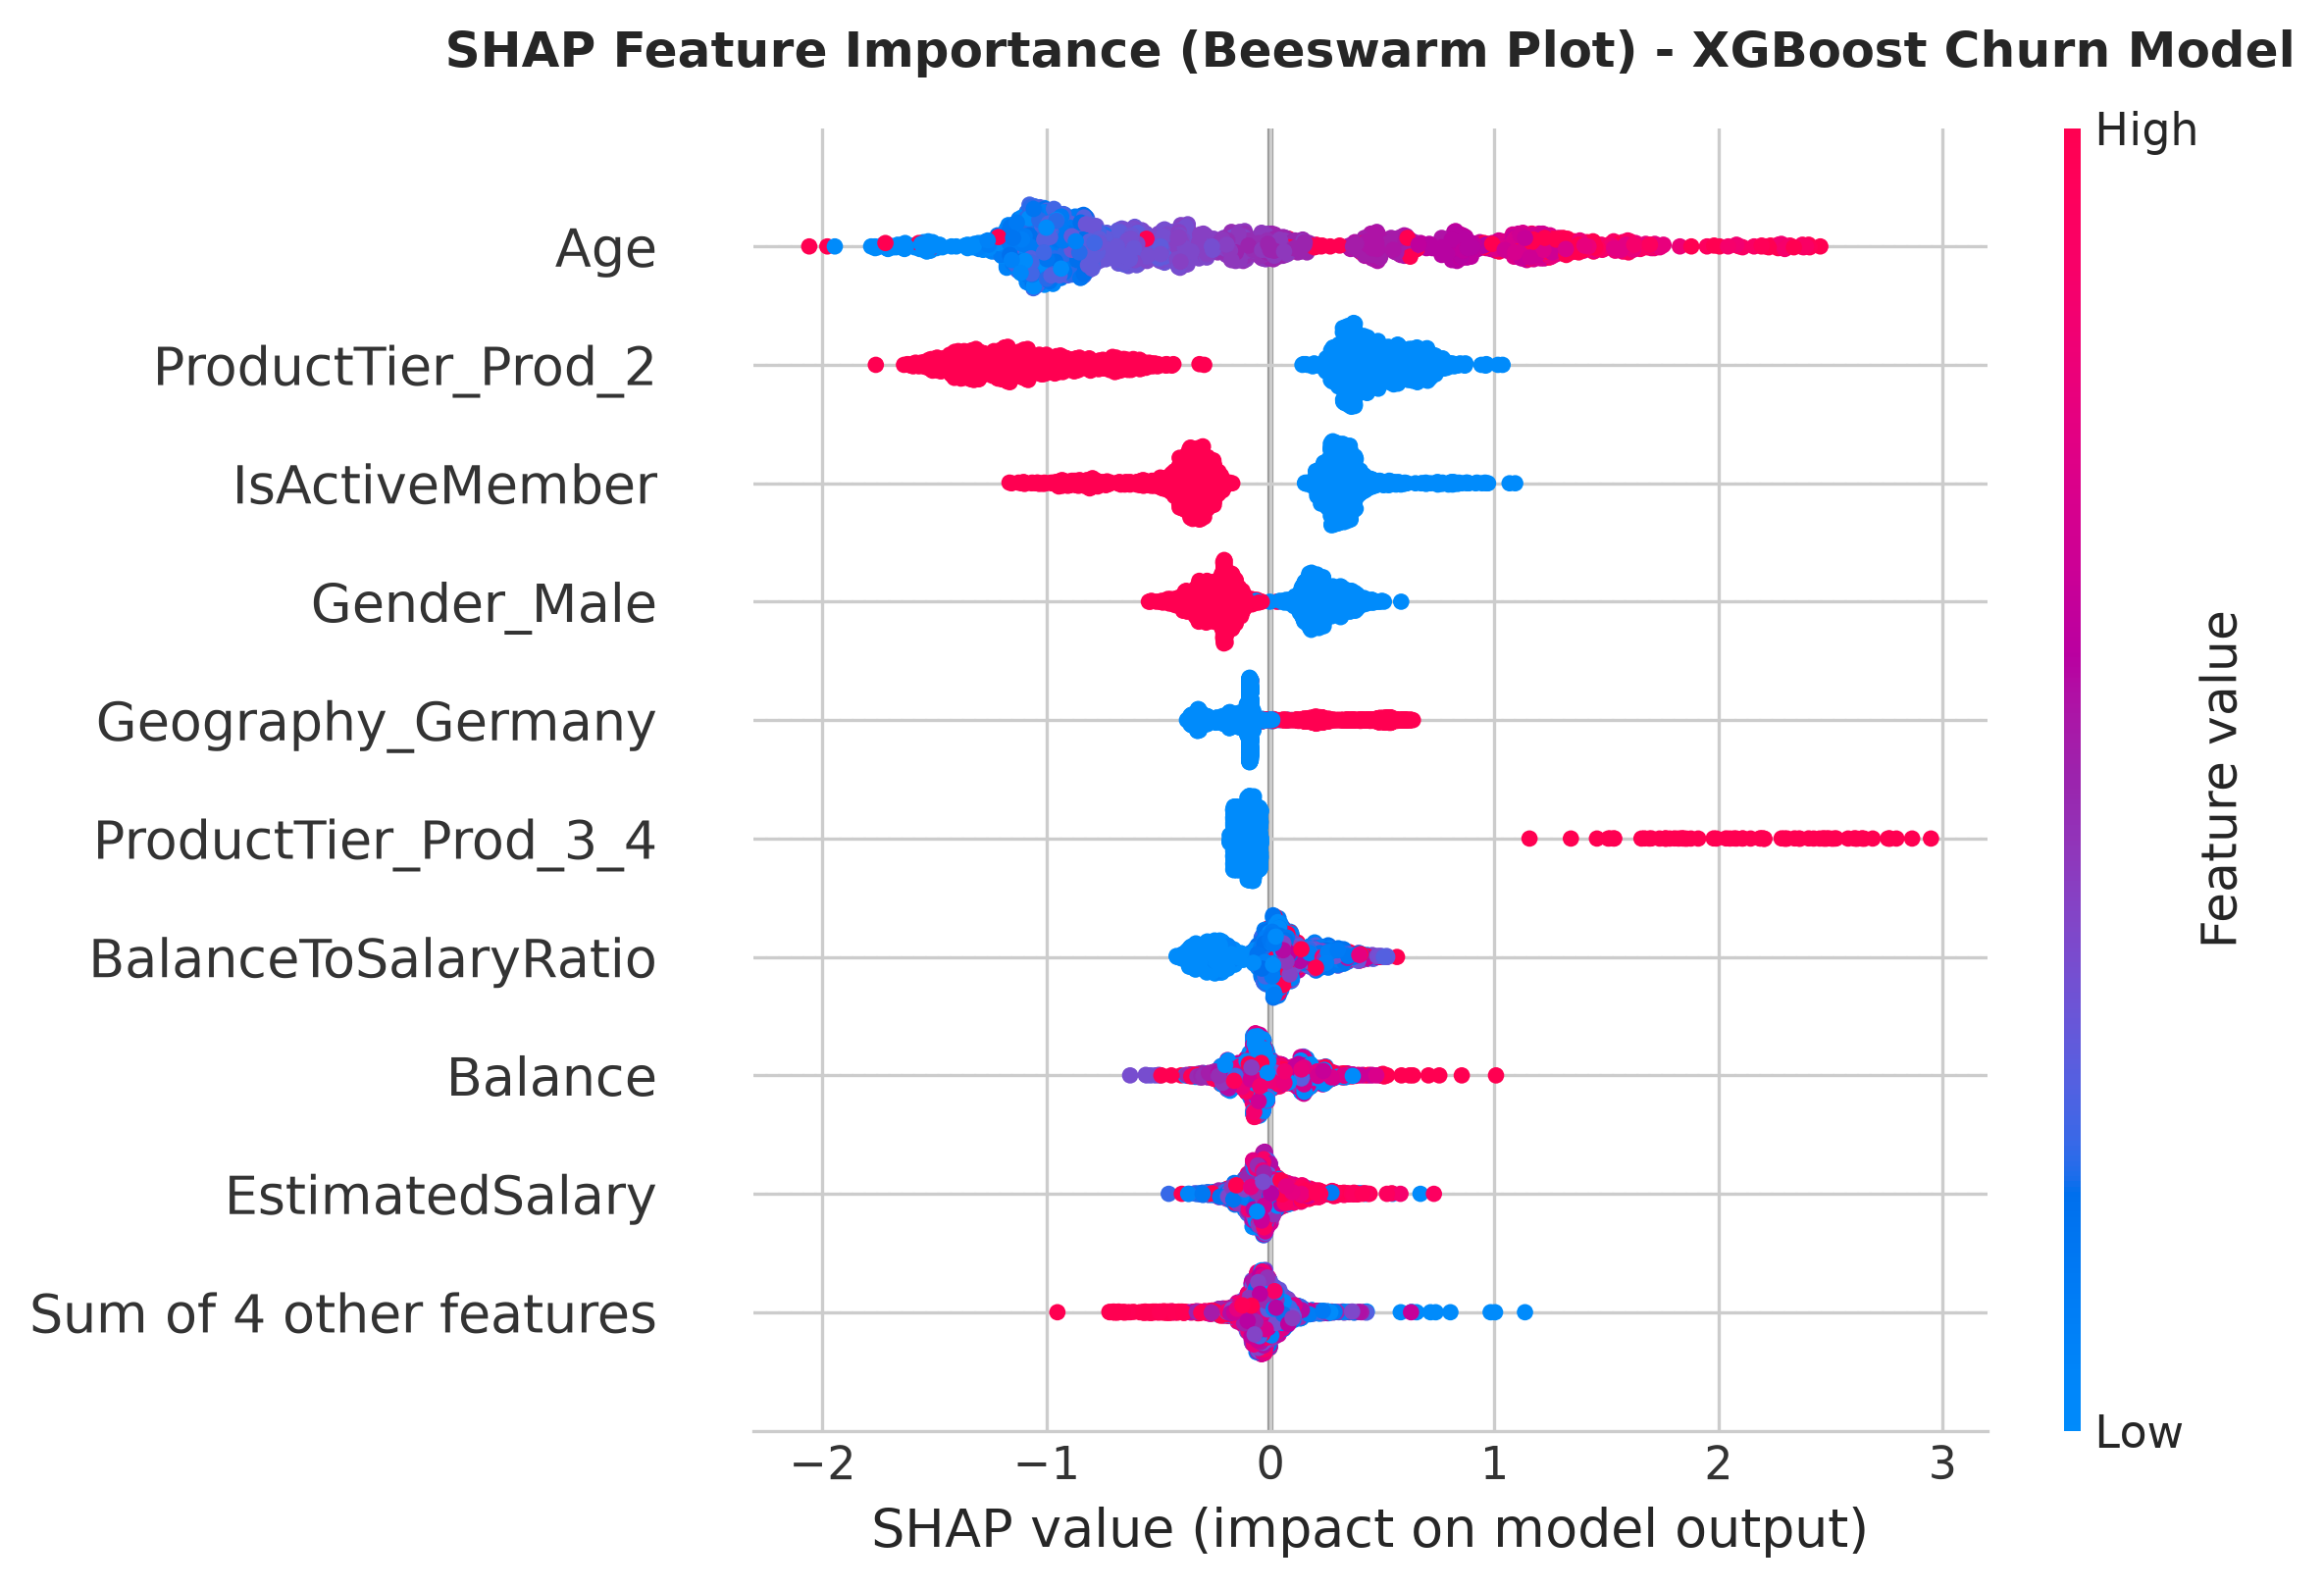


--- SHAP Bar Plot (reports/figures/06_shap_bar.png) ---


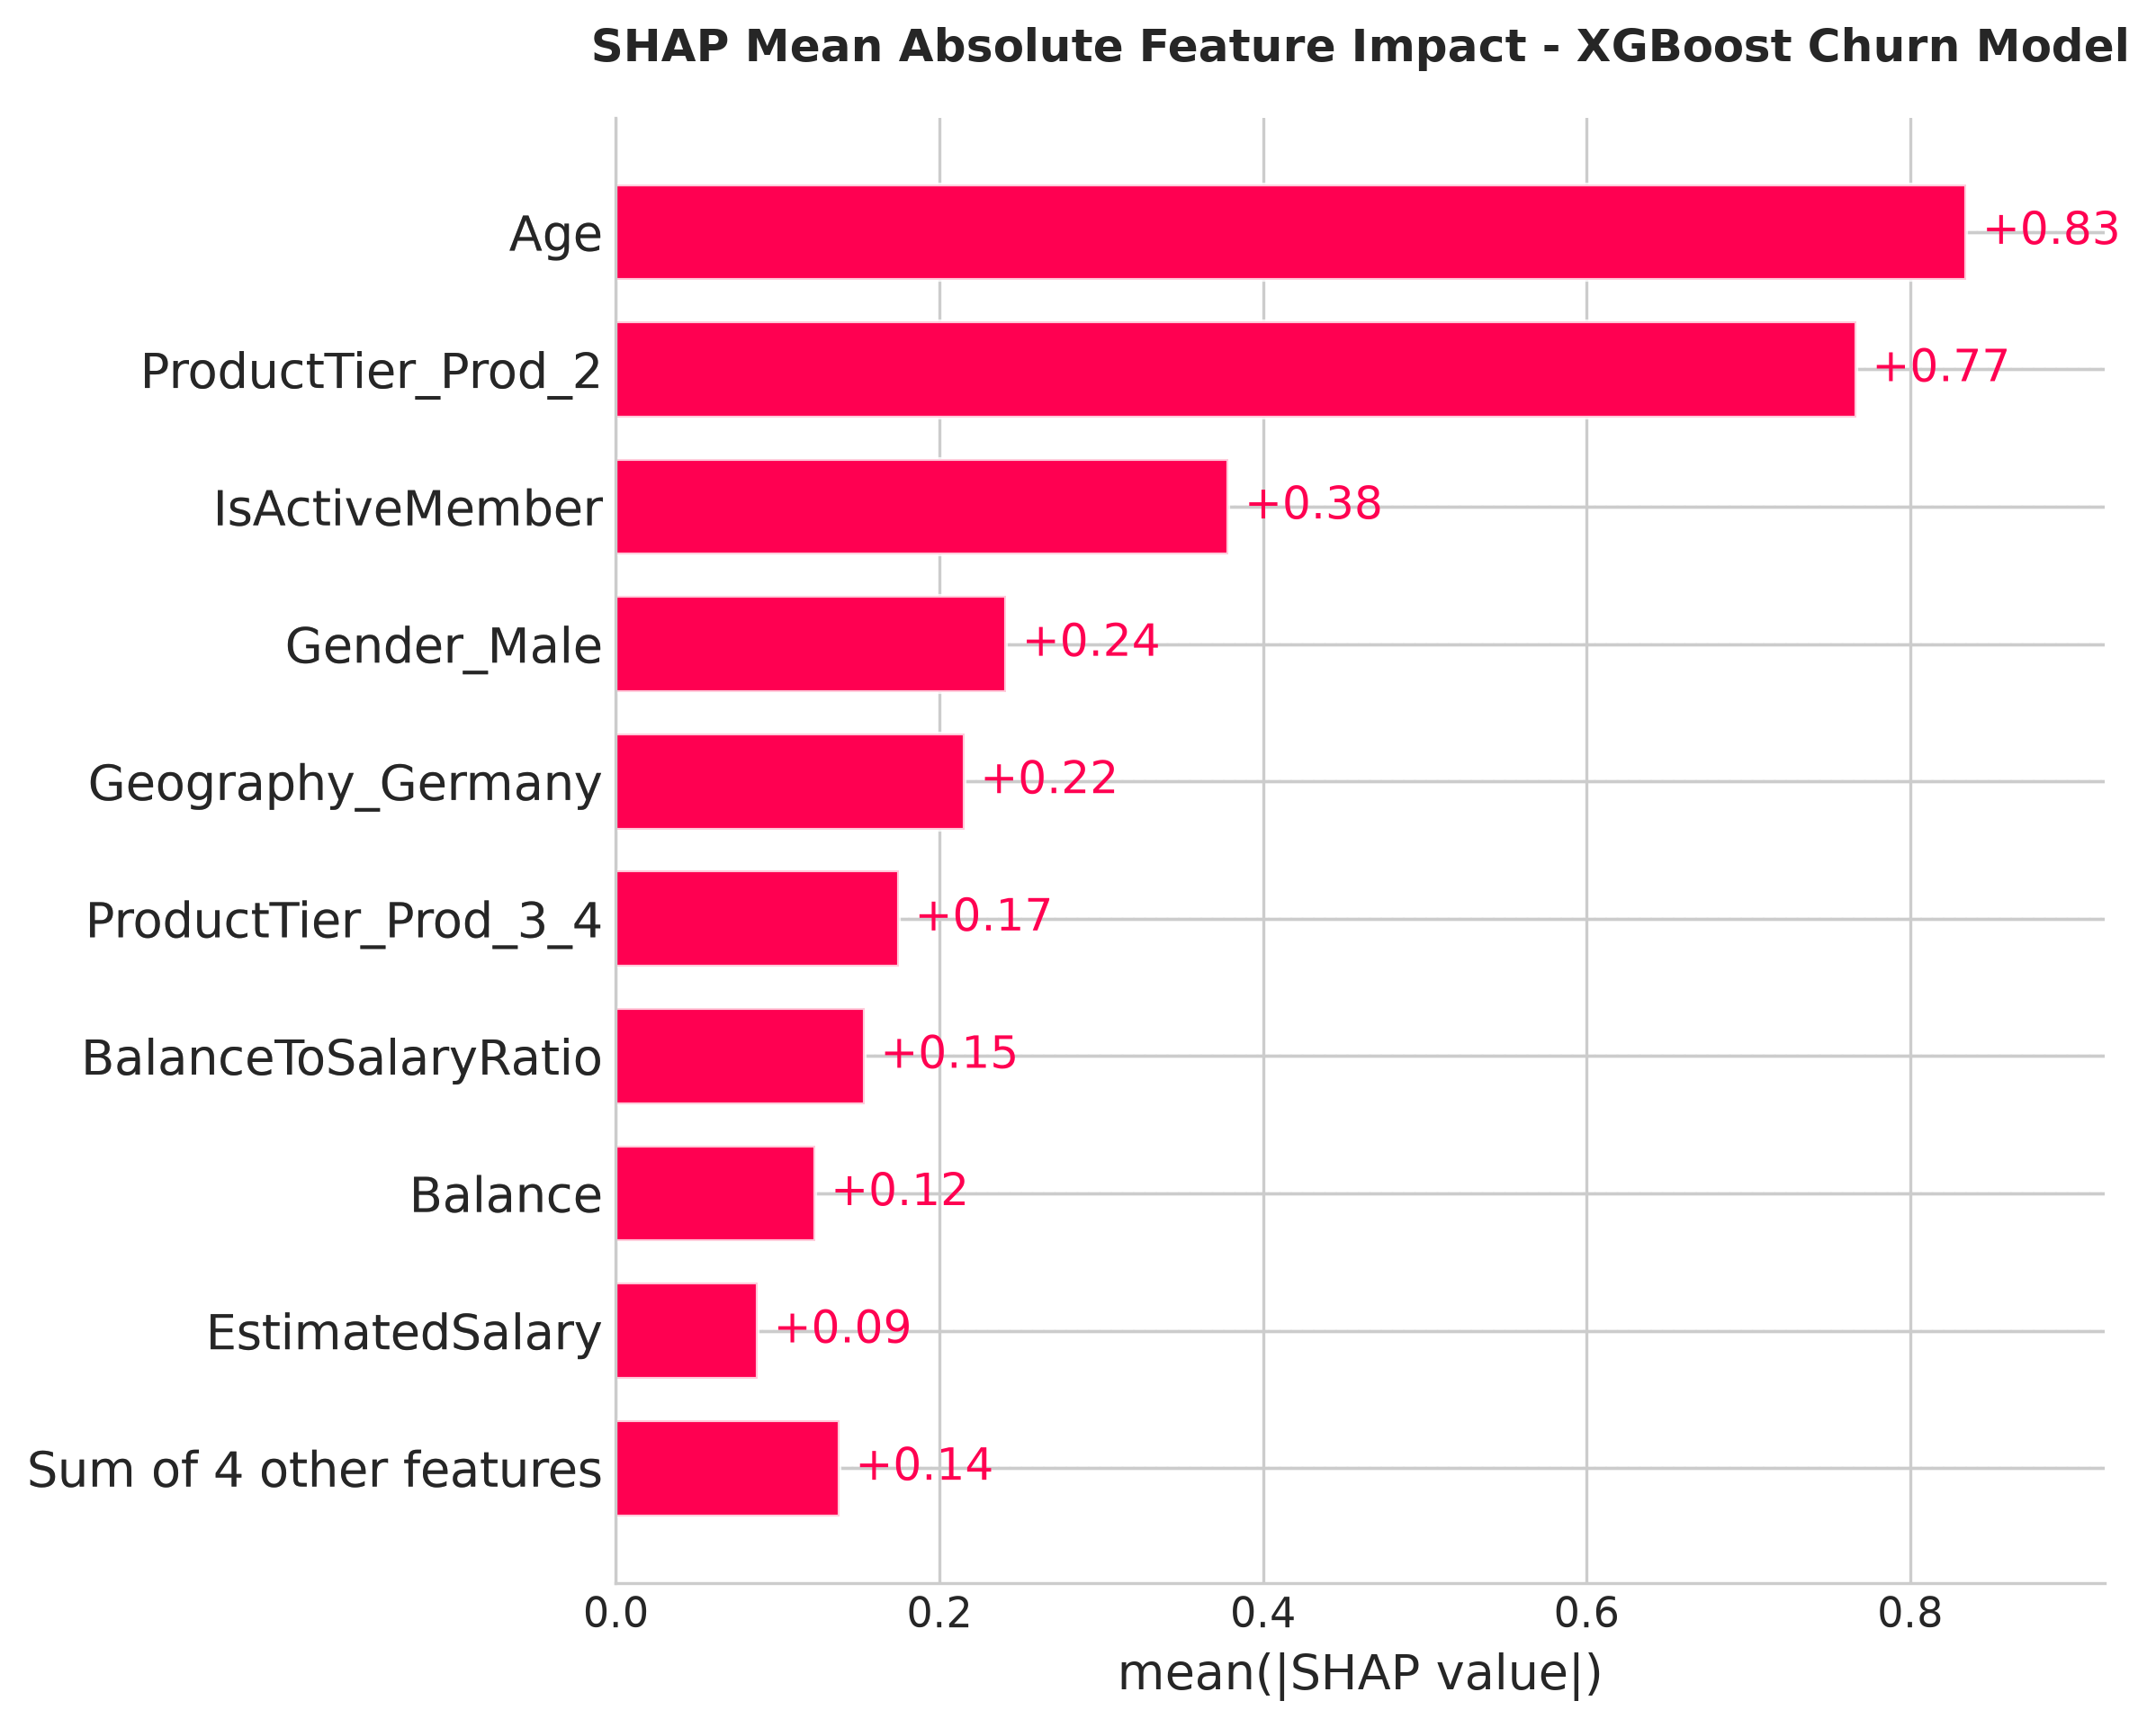


--- U6: Associative What-If Simulator Counterfactuals for Sample Inactive Customer ---


,Customer Profile Scenario,Scenario Description,Calibrated Churn Probability (%),Model-Predicted Difference vs Baseline,Nature of Evidence
0,Current Customer Baseline Profile,No modification to current customer attributes,65.23%,Baseline (0.00 pts),Model-predicted difference between similar pro...
1,Counterfactual Profile: Member Activation,Transition IsActiveMember from 0 to 1,44.66%,-20.57 pts,Model-predicted difference between similar pro...
2,Counterfactual Profile: Product Transition (1 ...,Transition NumOfProducts from 1 to 2 (Sweet Spot),4.53%,-60.70 pts,Model-predicted difference between similar pro...
3,WARNING: Excess Products Profile (to 3),Transition NumOfProducts to 3 (Friction Danger...,80.72%,+15.50 pts,Model-predicted difference between similar pro...
4,Counterfactual Profile: Credit Card Ownership,Transition HasCrCard from 0 to 1,65.35%,+0.12 pts,Model-predicted difference between similar pro...



--- U6 Similar-Cohort Observed Churn Rate & Population Counterfactual ---
  similar_cohort_size: 355
  similar_cohort_churn_rate: 0.24788732394366197
  similar_cohort_label: Spain, Age 31-45, Inactive, 1 Product
  population_size: 1597
  population_baseline_mean_prob: 0.2479540598439192
  population_counterfactual_mean_prob: 0.14758989726865232
  population_predicted_difference_pts: -10.036416257526687


Exported consolidated scored dataset to ../data/processed/bank_churn_scored.csv with 10000 rows and 20 columns.


In [17]:
# 5. U5: Retention Playbook & Scenario Balance Protection
playbook_table, scenarios_table = generate_retention_playbook(df_scored)
playbook_table.to_csv('../reports/tables/u5_retention_playbook.csv', index=False)
scenarios_table.to_csv('../reports/tables/u5_balance_protection_scenarios.csv', index=False)

print('--- U5: Strategic Retention Playbook (Tier Action Mapping) ---')
display(playbook_table)

print('\n--- U5: Scenario Balance Protection Simulations (Assumptions, Not Forecasts) ---')
display(scenarios_table)

# 6. Final Model Training, Probability Calibration, Decile Lift & SHAP Explainability
best_pipeline, model_metrics, lift_table, shap_notes = train_and_save_final_model(df_scored, random_state=42)
model_metrics.to_csv('../reports/tables/model_evaluation_metrics.csv', index=False)
lift_table.to_csv('../reports/tables/model_top_decile_lift.csv', index=False)
shap_notes.to_csv('../reports/tables/shap_plots_plain_language.csv', index=False)

print('\n--- Final Model Evaluation Metrics on Unseen Test Set (with 95% Bootstrap CIs) ---')
display(model_metrics)

print('\n--- Top 10% and Top 20% Risk Decile Precision, Recall, and Lift (Calibrated Model) ---')
display(lift_table)

print('\n--- SHAP Explanations in Plain Language ---')
display(shap_notes)

# Display saved SHAP figure artifacts
from IPython.display import Image, display as ipy_display
print('\n--- SHAP Summary Plot (reports/figures/06_shap_summary.png) ---')
ipy_display(Image(filename='../reports/figures/06_shap_summary.png'))

print('\n--- SHAP Bar Plot (reports/figures/06_shap_bar.png) ---')
ipy_display(Image(filename='../reports/figures/06_shap_bar.png'))

# 7. U6: Associative What-If Simulator Logic & Similar-Cohort Benchmarking
example_customer = df_scored[(df_scored['Exited'] == 0) & (df_scored['IsActiveMember'] == 0) & (df_scored['NumOfProducts'] == 1)].iloc[0]
what_if_table, benchmarks = simulate_customer_churn_change(example_customer, best_pipeline, full_df=df_tiered)
what_if_table.to_csv('../reports/tables/u6_what_if_simulation_examples.csv', index=False)

print('\n--- U6: Associative What-If Simulator Counterfactuals for Sample Inactive Customer ---')
display(what_if_table)
print('\n--- U6 Similar-Cohort Observed Churn Rate & Population Counterfactual ---')
for k, v in benchmarks.items():
    print(f"  {k}: {v}")

# 8. Single Consolidated Scored Dataset Export for Streamlit App
scored_export = export_consolidated_scored_file(df_scored, best_pipeline, output_path='../data/processed/bank_churn_scored.csv')


### Section 7 Key Findings & Regulatory Modeling Summary
- **U1 Data-Driven RSI Definition & Calibration:** RSI is defined as `100 x predicted probability of staying` from the behavioral logistic regression model. Because logistic regression fitted via maximum likelihood with an intercept satisfies the score equation sum(y_i - p_i) = 0, its average predicted probability of staying on the training set equals the empirical retention rate (79.63%). Data-driven RSI achieves a test ROC-AUC of **0.7514**, significantly outperforming Naive RSI 1 (**0.6874**, paired delta: +0.0640, 95% CI: [0.0471, 0.0814]) and Naive RSI 2 (**0.7054**, paired delta: +0.0460, 95% CI: [0.0322, 0.0607]). Active membership has a coefficient of **-0.813 on churn log-odds** (reducing churn risk), while inactive membership is +0.813.
- **U2 Behavior vs. Demographics Paired Bootstrap Finding:** The paired bootstrap difference between Behavioral-only and Demographic-only models yields a delta ROC-AUC of **-0.0112** (95% CI: [-0.0445, +0.0232]) and a delta PR-AUC of **+0.0405** (95% CI: [-0.0218, +0.0999]). Because both confidence intervals span zero, behavioral features are **not statistically significantly superior** to demographic features in isolation. They are about **equally informative and complementary**: demographics (Age, Geography) establishes non-actionable baseline exposure, while behavioral features capture current customer relationship health and are directly actionable for retention interventions. Combining both yields an ROC-AUC of **0.8690** (95% CI: [0.8474, 0.8891]) and PR-AUC of **0.7171** (95% CI: [0.6758, 0.7555]).
- **U3 Sizing Hollow Premium Capital (Risk-Weighted Balance):** Among customers currently retained (Exited = 0), there are **1,079 Hollow Premium customers** holding **155,004,893.37** in nominal deposits, facing an expected Value-at-Risk of **30,944,693.58**. VaR is a risk-weighted balance for ranking and relative sizing, not a 1-year financial loss forecast. All retained customers have an average calibrated churn probability of **13.13%**, whereas the Hollow Premium group averages **19.95%**. Hollow Premium is defined by observable business attributes; an explicit RSI condition was left out to avoid coupling segment definitions to model iterations, but Hollow Premium customers naturally exhibit depressed RSI scores (mean 80.05 vs. 86.87 for all retained customers).
- **U4 Statistical Rigor & Mann-Whitney Benchmark:** Formal hypothesis testing confirms Product Depth (chi2 = 1494.60, Cramer's V = 0.3866), Geography (chi2 = 301.26, Cramer's V = 0.1736), and Active Membership (chi2 = 242.99, Cramer's V = 0.1559) are statistically significant after Bonferroni and Holm corrections. Credit Card Ownership fails significance (p = 0.4924). The Mann-Whitney U test comparing **Funded High Balance (>= 119k) vs. Funded Lower Balance (< 119k) among accounts with Balance > 0** confirms no statistically significant difference in churn rates (U = 5,103,622, p = 0.8432, rank-biserial r = -0.0021).
- **U5 Strategic Retention Playbook:** Cross-selling is strictly limited to 1-product customers as a **candidate for a pilot test (A/B)** toward the 2-product sweet spot. For 3-4 product customers, banks must **avoid pushing a third product until tested** (only **46 retained customers** currently hold 3-4 products across the bank; fee fatigue and operational complexity are possible explanations we cannot test with this data). Retaining 10% to 30% of at-risk capital corresponds to an illustrative 9.29M to 27.88M in protected balance.
- **U6 Calibrated What-If Simulator & Population Counterfactual:** The simulator utilizes the calibrated pipeline. For an illustrative Spain Inactive 1-Product customer (Age 31-45), the calibrated baseline is benchmarked against an observed historical churn rate of **24.79%** (n = 355) for similar customer profiles. At the population level across all **1,597 retained inactive 1-product customers**, the model predicts an average churn drop of **-10.04 percentage points** (from 24.80% to 14.76%) if they became active. All counterfactuals reflect model-predicted differences between similar customer profiles, not proven causal outcomes.
- **Top-Decile Operational Lift:** Top 10% highest-risk customers (n = 200) achieve **86.00% precision**, **42.26% recall**, and **4.23x lift**. Top 20% highest-risk customers (n = 400) achieve **64.00% precision**, **62.90% recall**, and **3.14x lift**, allowing the bank to capture nearly 63% of all churners by contacting only 20% of its customer base.
